# TRABAJO FIN DE GRADO: Detección de TEA mediante sistemas de IA

#### **Estudiante**: Ángel Vilariño García
#### **Dirección**: Verónica Bolón Canedo y Brais Cancela Barizo

### **1. Carga de datos y análisis inicial**

#### 1.1. Carga de datos

In [1]:
# Cargamos el archivo de datos .sav

# Librerías estándar
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Librerías de datos y numeración
import pandas as pd
import pyreadstat
import numpy as np
import missingno as msno

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reducción de dimensionalidad
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Configuración global de colores y guardado de figuras
PALETA_DIAG = {'Control': 'tomato', 'TEA': 'steelblue'}
PALETA_DIAG_NUM = {1.0: 'tomato', 2.0: 'steelblue'}
DIR_GRAFICAS = Path('graficas_EDA')
DIR_GRAFICAS.mkdir(exist_ok=True)

def guardar_grafica(nombre_archivo, fig=None, dpi=300):
    if fig is None:
        fig = plt.gcf()
    ruta = DIR_GRAFICAS / nombre_archivo
    fig.savefig(ruta, dpi=dpi, bbox_inches='tight')

df_sav, meta = pyreadstat.read_sav("TEA_1.sav")

df_sav.head()

2026-04-06 12:38:45.187290: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


,Nombre,Institución,Pais,Edad,Sexo,Altura,Peso,M_expresion,Estado_legal,Diag_secundario,...,actsococ2,act_lim3,estereotip,estereotipq,comunic,comunicq,intsoc,intsocq,habla,Diag_primario
0,G,1.0,1.0,8.0,1.0,120.0,30.0,1.0,2.0,3.0,...,1.0,1.0,30.0,4.0,18.0,1.0,34.0,3.0,0.0,1.0
1,MR,2.0,2.0,2.0,1.0,70.0,20.0,1.0,2.0,1.0,...,NaN,NaN,27.0,3.0,41.0,4.0,39.0,4.0,0.0,2.0
2,NR,2.0,2.0,5.0,2.0,95.0,25.0,2.0,2.0,3.0,...,NaN,NaN,28.0,3.0,25.0,2.0,28.0,2.0,1.0,2.0
3,AF,2.0,2.0,7.0,1.0,155.0,40.0,2.0,2.0,1.0,...,NaN,NaN,23.0,2.0,35.0,4.0,33.0,3.0,1.0,2.0
4,NL,2.0,2.0,7.0,2.0,125.0,35.0,2.0,2.0,1.0,...,NaN,NaN,28.0,3.0,39.0,4.0,42.0,4.0,1.0,2.0


In [2]:
tabla_pais_institucion = pd.crosstab(df_sav['Pais'], df_sav['Institución'])
print(tabla_pais_institucion)

Institución  1.0  2.0
Pais                 
1.0           60   10
2.0           94   45


#### 1.2. Dimensión del dataset

In [3]:
# Mostramos el número de filas y columnas del DataFrame

print("Número de muestras:", df_sav.shape[0])
print("Número de características:", df_sav.shape[1])

Número de muestras: 209
Número de características: 217


#### 1.3. Tipos de variables

In [4]:
# Clasificación de variables por tipo (criterio del proyecto)
# Supuesto validado: todas las variables numéricas son categóricas codificadas,
# excepto Edad, Altura y Peso. Además, Nombre es identificador textual.

n_total = df_sav.shape[1]

col_id_texto = ['Nombre']
col_continuas = ['Edad', 'Altura', 'Peso']

numeric_cols = list(df_sav.select_dtypes(include='number').columns)
non_numeric_cols = list(df_sav.select_dtypes(exclude='number').columns)

categoricas_codificadas = [c for c in numeric_cols if c not in col_continuas]

print(f"Total variables:                         {n_total}")
print(f"  · Categóricas codificadas (numéricas): {len(categoricas_codificadas)}")
print(f"  · Continuas numéricas:                 {len(col_continuas)}")
print(f"  · Texto/identificador:                 {len(col_id_texto)}")

print("\nVariables continuas:")
print(col_continuas)

print("\nVariable textual identificadora:")
print(col_id_texto)

Total variables:                         217
  · Categóricas codificadas (numéricas): 213
  · Continuas numéricas:                 3
  · Texto/identificador:                 1

Variables continuas:
['Edad', 'Altura', 'Peso']

Variable textual identificadora:
['Nombre']


#### 1.4. Descripción de las variables

In [5]:
# Mostramos los nombres de las columnas y su descripción

print("\nNombres columna y descripción:\n")

for col, label in zip(meta.column_names, meta.column_labels):
    print(f"{col}: {label}")


Nombres columna y descripción:

Nombre: Nombre
Institución: Institución
Pais: País de procedencia
Edad: Edad
Sexo: Sexo
Altura: Estatura
Peso: Peso
M_expresion: Modo principal de expresión
Estado_legal: Estado legal
Diag_secundario: Diagnósticos secundarios
Apoyos: Apoyos
Visión: Visión
Audición: Audición
At_epilpticos: Frecuencia de ataques epilépticos
Salud: Salud
Atencion_enfermero: Necesita de la atención de una enfermero o médico.
Medicamentos: Medicamentos que toma actualmente
Movilidad: Movilidad
Ayudas_movilidad: Ayudas para su movilidad
coger_objetos: 1.1 Coge objetos pequeños con la mano.
Pasa_objetos: 1.2 Pasa objetos pequeños de una mano a otra.
sienta_solo_cabeza: 1.3 Se sienta solo/a, manteniendo la cabeza y la espalda derecha y firmes durante 30 segundos.
mantiene_en_pie: 1.4 Se mantiene en pie, al menos durante cinco segundos, apoyándose en muebles u otros objetos.
en_pone_en_pie: 1.5 Se pone en pie por sí mismo/a.
mete_objetos_pequeños: 1.6 Mete objetos pequeños en re

#### 1.5. Explicación de la codificación de variables categóricas

In [6]:
# Mostramos codificaciones de las variables categóricas

print("\nCodificaciones de variables categóricas:\n")

for col in meta.column_names:
    if col in meta.variable_value_labels:
        print(f"{col} codificaciones:")
        for code, meaning in meta.variable_value_labels[col].items():
            print(f"  {code}: {meaning}")
        print()


Codificaciones de variables categóricas:

Institución codificaciones:
  1.0: Especial
  2.0: Ordinario

Pais codificaciones:
  1.0: Uruguay
  2.0: Galicia

Sexo codificaciones:
  1.0: hombre
  2.0: Mujer

M_expresion codificaciones:
  1.0: No verbal
  2.0: Verbal

Estado_legal codificaciones:
  1.0: Familia de acogida
  2.0: Familia biológica
  5.0: otro

Diag_secundario codificaciones:
  1.0: ninguno
  2.0: ceguera
  3.0: lesión cerebral
  4.0: paralísis cerebral
  5.0: Retraso Mental
  6.0: Enfermedade fisiolóxica
  7.0: Enfermedade Mental

Apoyos codificaciones:
  1.0: No necesita apoyo
  2.0: Necesita apoyo
  3.0: Necesita apoyo notable
  4.0: Necesita apoyo muy notable

Visión codificaciones:
  1.0: Visión Buena
  2.0: Problemas de Visión que limitan la lectura o su movilidad
  3.0: Poco o nula visión (incluso con lentes)

Audición codificaciones:
  1.0: Puede oir voces normales (con o sin audífono)
  2.0: Puede oir voces altas (con o sin audífono)
  3.0: Audiciones pobre o nula 

#### 1.5.1. Exportación automática de metadatos

En esta celda se genera y guarda el archivo `Metadata.md` con la descripción y codificación de todas las variables del dataset.

In [7]:
# Crear archivo Markdown con metadatos completos

with open("Metadata.md", "w", encoding="utf-8") as f:
    # Encabezado general
    f.write("# Metadatos del conjunto de datos TEA\n\n")
    f.write("Tabla con las variables, sus descripciones y las posibles codificaciones categóricas (si las hay):\n\n")

    # Cabecera de la tabla
    f.write("| **Variable** | **Descripción** | **Codificación** |\n")
    f.write("|---------------|-----------------|------------------|\n")

    # Recorrer las variables
    for col, label in zip(meta.column_names, meta.column_labels):
        # Obtener codificaciones (si existen)
        if col in meta.variable_value_labels:
            mapping = meta.variable_value_labels[col]
            # Cada par código: significado en una línea separada usando <br>
            codif = "<br>".join([f"**{k}**: {v}" for k, v in mapping.items()])
        else:
            codif = ""

        label = str(label).replace("|", "‖")
        codif = str(codif).replace("|", "‖")

        # Escribir línea de la tabla
        f.write(f"| {col} | {label} | {codif} |\n")

#### 1.6. Tipo de datos de las variables

In [8]:
# Mostramos el tipo de datos de cada columna

print("\nTipos de datos de las columnas:\n")
for col in meta.column_names:
    print(f"Columna '{col}': {df_sav[col].dtype}")


Tipos de datos de las columnas:

Columna 'Nombre': object
Columna 'Institución': float64
Columna 'Pais': float64
Columna 'Edad': float64
Columna 'Sexo': float64
Columna 'Altura': float64
Columna 'Peso': float64
Columna 'M_expresion': float64
Columna 'Estado_legal': float64
Columna 'Diag_secundario': float64
Columna 'Apoyos': float64
Columna 'Visión': float64
Columna 'Audición': float64
Columna 'At_epilpticos': float64
Columna 'Salud': float64
Columna 'Atencion_enfermero': float64
Columna 'Medicamentos': float64
Columna 'Movilidad': float64
Columna 'Ayudas_movilidad': float64
Columna 'coger_objetos': float64
Columna 'Pasa_objetos': float64
Columna 'sienta_solo_cabeza': float64
Columna 'mantiene_en_pie': float64
Columna 'en_pone_en_pie': float64
Columna 'mete_objetos_pequeños': float64
Columna 'camina_dos_metros': float64
Columna 'Hace_rayas_papel': float64
Columna 'quita_envoltorio': float64
Columna 'gira_manillas': float64
Columna 'sube_y_baja_escaleras': float64
Columna 'sube_escaler

#### 1.7. Análisis de valores nulos

In [9]:
# Mostramos los valores nulos por columna en las columnas donde hay nulos

print("\nColumnas con valores nulos:\n")

null_counts = df_sav.isnull().sum()
for col, count in null_counts.items():
    if count > 0:
        # Añadimos también el porcentaje de valores nulos
        percent = (count / df_sav.shape[0]) * 100
        print(f"{col}: {count} ({percent:.2f}%)")


Columnas con valores nulos:

Medicamentos: 1 (0.48%)
sube_y_baja_escaleras: 1 (0.48%)
cumple_citas: 1 (0.48%)
franja_etaria: 100 (47.85%)
diag_sec2: 100 (47.85%)
diag_sec3: 100 (47.85%)
vis2c: 102 (48.80%)
Visaud: 102 (48.80%)
enfermedad: 102 (48.80%)
motoras: 104 (49.76%)
motorq: 104 (49.76%)
sociales: 104 (49.76%)
socialq: 104 (49.76%)
vitales: 104 (49.76%)
vitalq: 104 (49.76%)
comunitarias: 104 (49.76%)
comunq: 104 (49.76%)
Frec_autoles3: 140 (66.99%)
grav_autoles3: 140 (66.99%)
grav_autoles2: 140 (66.99%)
frec_hetragrs3: 140 (66.99%)
grav_hetragr2: 140 (66.99%)
frec_destr3: 140 (66.99%)
frec_destr2: 140 (66.99%)
frec_disr3: 139 (66.51%)
grav_disr3: 139 (66.51%)
grav_disr2: 139 (66.51%)
frec_rep3: 141 (67.46%)
frec_ofens4: 139 (66.51%)
grav_ofens2: 139 (66.51%)
frec_retrm3: 139 (66.51%)
grav_retrm3: 139 (66.51%)
Frec_nocol3: 139 (66.51%)
Frec_nocol2: 139 (66.51%)
grav_nocol2: 139 (66.51%)
reac_condprb3: 141 (67.46%)
serv_act2: 141 (67.46%)
serv_apoyact3: 146 (69.86%)
act_sococ3: 16

#### 1.7.1. Visualización de patrón de datos ausentes

Se muestra una matriz de missing values para detectar patrones sistemáticos de ausencia y posibles sesgos de medición.

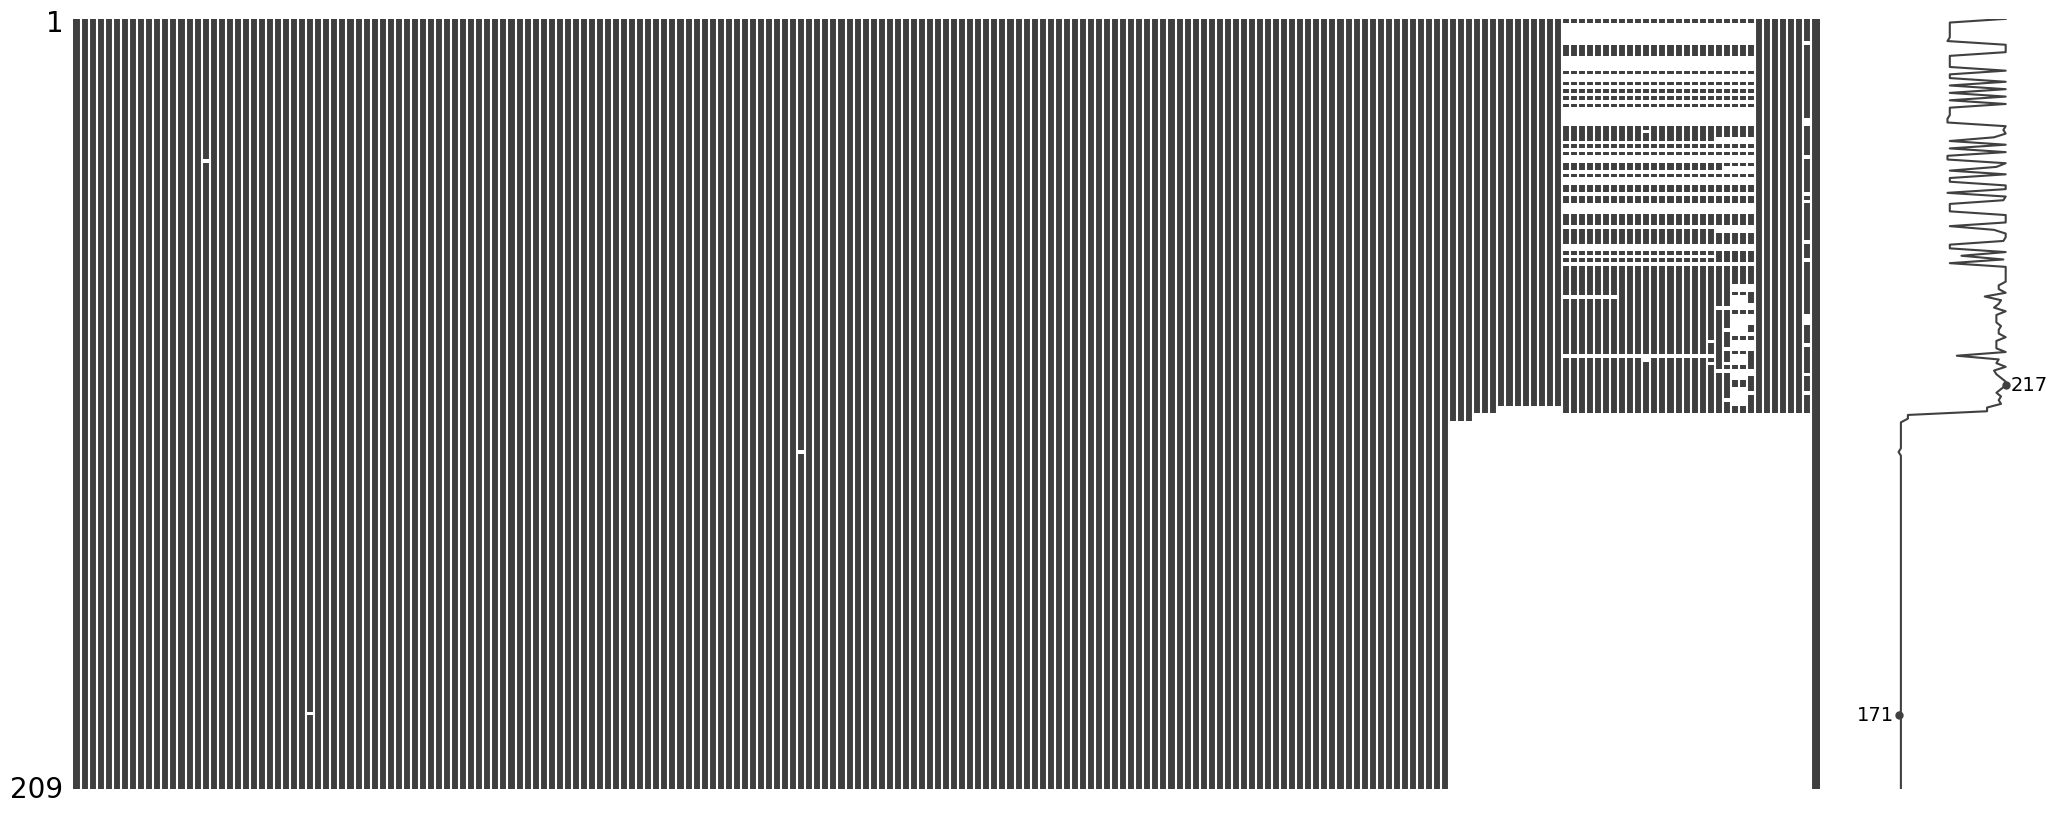

In [10]:
# Visualización de valores nulos usando missingno

msno.matrix(df_sav)
guardar_grafica('01_missing_matrix.png')
plt.show()

**NOTA:** Una cantidad significativa de variables presentan más de la mitad de sus valores como nulos. Esto puede tenerse en cuenta a la hora del preprocesamiento de los datos, y/o la posterior selección de características para el entrenamiento de modelos.

In [11]:
# Análisis cuantitativo de valores nulos
null_counts  = df_sav.isnull().sum()
null_pct     = (null_counts / len(df_sav) * 100).round(1)
missing_df   = pd.DataFrame({'n_nulos': null_counts, 'pct_nulos': null_pct})
missing_df   = missing_df[missing_df['n_nulos'] > 0].sort_values('pct_nulos', ascending=False)

print(f"Variables con algún valor nulo: {len(missing_df)} de {df_sav.shape[1]}")
print(f"Variables con >50% nulos:       {(missing_df['pct_nulos'] > 50).sum()}")
print(f"Variables con >75% nulos:       {(missing_df['pct_nulos'] > 75).sum()}")
print("\nTop 15 variables con más nulos:")
print(missing_df.head(15).to_string())

Variables con algún valor nulo: 48 de 217
Variables con >50% nulos:       25
Variables con >75% nulos:       2

Top 15 variables con más nulos:
                n_nulos  pct_nulos
act_sococ3          166       79.4
actsococ2           166       79.4
act_lim3            154       73.7
serv_apoyact3       146       69.9
serv_act2           141       67.5
reac_condprb3       141       67.5
frec_rep3           141       67.5
Frec_autoles3       140       67.0
grav_autoles3       140       67.0
grav_autoles2       140       67.0
frec_hetragrs3      140       67.0
frec_destr2         140       67.0
grav_hetragr2       140       67.0
frec_destr3         140       67.0
frec_disr3          139       66.5


#### 1.7.2. Missings estratificados por país

Se evalúa si la ausencia de datos depende del país de procedencia en variables con alto porcentaje de nulos.

In [12]:
# Patrón de missings en países
pais_labels = {1.0: 'Uruguay', 2.0: 'Galicia'}
df_sav['Pais_label'] = df_sav['Pais'].map(pais_labels)

# Variables con >50% nulos globales
vars_muchos_nulos = missing_df[missing_df['pct_nulos'] > 50].index.tolist()

print("Porcentaje de nulos por país en variables con >50% de missings globales:\n")
for var in vars_muchos_nulos:
    pct_por_pais = df_sav.groupby('Pais_label')[var].apply(
        lambda x: x.isnull().mean() * 100
    ).round(1)
    print(f"  {var}: {pct_por_pais.to_dict()}")

Porcentaje de nulos por país en variables con >50% de missings globales:

  act_sococ3: {'Galicia': 98.6, 'Uruguay': 41.4}
  actsococ2: {'Galicia': 98.6, 'Uruguay': 41.4}
  act_lim3: {'Galicia': 98.6, 'Uruguay': 24.3}
  serv_apoyact3: {'Galicia': 98.6, 'Uruguay': 12.9}
  serv_act2: {'Galicia': 98.6, 'Uruguay': 5.7}
  reac_condprb3: {'Galicia': 98.6, 'Uruguay': 5.7}
  frec_rep3: {'Galicia': 98.6, 'Uruguay': 5.7}
  Frec_autoles3: {'Galicia': 98.6, 'Uruguay': 4.3}
  grav_autoles3: {'Galicia': 98.6, 'Uruguay': 4.3}
  grav_autoles2: {'Galicia': 98.6, 'Uruguay': 4.3}
  frec_hetragrs3: {'Galicia': 98.6, 'Uruguay': 4.3}
  frec_destr2: {'Galicia': 98.6, 'Uruguay': 4.3}
  grav_hetragr2: {'Galicia': 98.6, 'Uruguay': 4.3}
  frec_destr3: {'Galicia': 98.6, 'Uruguay': 4.3}
  frec_disr3: {'Galicia': 98.6, 'Uruguay': 2.9}
  frec_ofens4: {'Galicia': 98.6, 'Uruguay': 2.9}
  Frec_nocol2: {'Galicia': 98.6, 'Uruguay': 2.9}
  grav_retrm3: {'Galicia': 98.6, 'Uruguay': 2.9}
  grav_ofens2: {'Galicia': 98.6, 'Ur

#### 1.8. Análisis de balance de clases

Distribución de la variable objetivo (Diag_primario):
Diag_grupo
TEA        111
Control     98

Ratio TEA/Control: 1.13
Desbalance relativo: 6.2% de diferencia


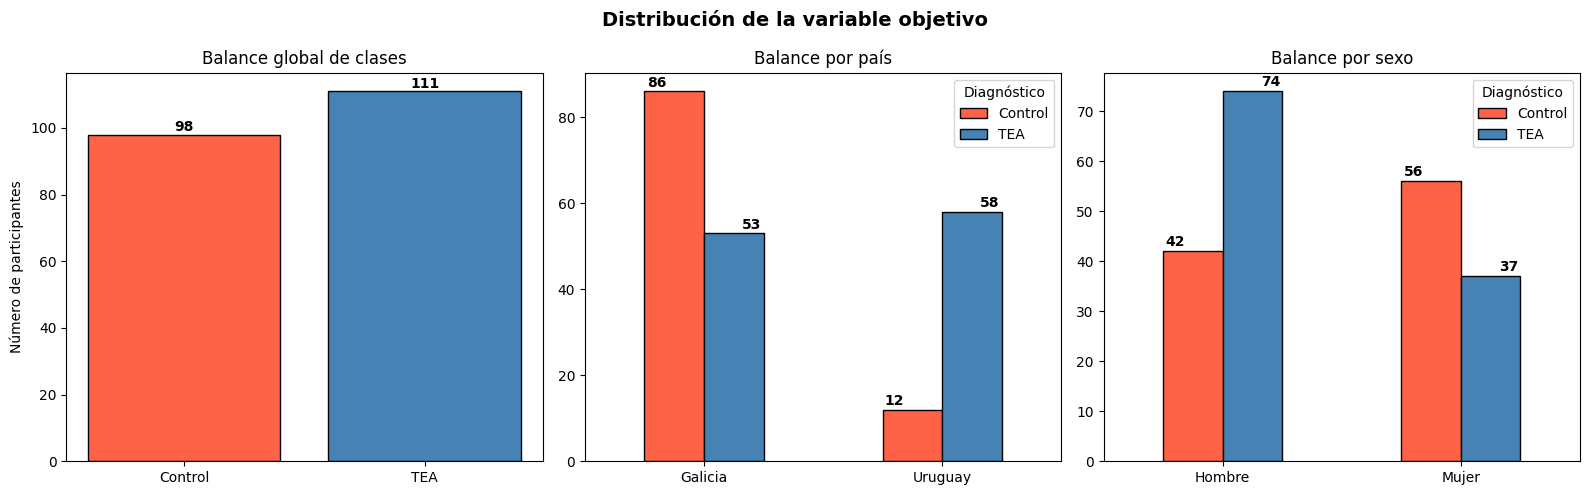

In [13]:
# Balance de clases

diag_labels = {1.0: 'Control', 2.0: 'TEA'}
df_sav['Diag_grupo'] = df_sav['Diag_primario'].map(diag_labels)

# Etiquetas auxiliares (autosuficiente)
pais_labels = {1.0: 'Uruguay', 2.0: 'Galicia'}
sexo_labels = {1.0: 'Hombre', 2.0: 'Mujer'}
df_sav['Pais_label'] = df_sav['Pais'].map(pais_labels)
df_sav['Sexo_label'] = df_sav['Sexo'].map(sexo_labels)

conteo = df_sav['Diag_grupo'].value_counts()
print("Distribución de la variable objetivo (Diag_primario):")
print(conteo.to_string())
print(f"\nRatio TEA/Control: {conteo['TEA']/conteo['Control']:.2f}")
print(f"Desbalance relativo: {abs(conteo['TEA']-conteo['Control'])/len(df_sav)*100:.1f}% de diferencia")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Balance global
orden = ['Control', 'TEA']
vals = [conteo.get(x, 0) for x in orden]
axes[0].bar(orden, vals, color=[PALETA_DIAG[x] for x in orden], edgecolor='black')
for i, (label, val) in enumerate(zip(orden, vals)):
    axes[0].text(i, val + 1, str(val), ha='center', fontweight='bold')
axes[0].set_title('Balance global de clases')
axes[0].set_ylabel('Número de participantes')

# 2. Balance por país
conteo_pais = df_sav.groupby(['Pais_label', 'Diag_grupo']).size().unstack(fill_value=0)
conteo_pais = conteo_pais.reindex(columns=orden)
conteo_pais.plot(kind='bar', ax=axes[1], color=[PALETA_DIAG[x] for x in orden], edgecolor='black', rot=0)
for i, diag in enumerate(conteo_pais.columns):
    for j, pais in enumerate(conteo_pais.index):
        val = conteo_pais.loc[pais, diag]
        axes[1].text(j + (i-0.5)*0.4, val + 1, str(val), ha='center', fontweight='bold')
axes[1].set_title('Balance por país')
axes[1].set_xlabel('')
axes[1].legend(title='Diagnóstico')

# 3. Balance por sexo
conteo_sexo = df_sav.groupby(['Sexo_label', 'Diag_grupo']).size().unstack(fill_value=0)
conteo_sexo = conteo_sexo.reindex(columns=orden)
conteo_sexo.plot(kind='bar', ax=axes[2], color=[PALETA_DIAG[x] for x in orden], edgecolor='black', rot=0)
for i, diag in enumerate(conteo_sexo.columns):
    for j, sexo in enumerate(conteo_sexo.index):
        val = conteo_sexo.loc[sexo, diag]
        axes[2].text(j + (i-0.5)*0.4, val + 1, str(val), ha='center', fontweight='bold')
axes[2].set_title('Balance por sexo')
axes[2].set_xlabel('')
axes[2].legend(title='Diagnóstico')

plt.suptitle('Distribución de la variable objetivo', fontsize=14, fontweight='bold')
guardar_grafica('02_balance_clases_global_pais_sexo.png', fig)
plt.tight_layout()
plt.show()

### **2. Análisis exploratorio**

#### 2.1. Resumen estadístico general

In [14]:
# Resumen estadístico general

print("\nResumen estadístico general:\n")
print(df_sav.describe(include='all'))


Resumen estadístico general:

       Nombre  Institución        Pais        Edad        Sexo      Altura  \
count     209   209.000000  209.000000  209.000000  209.000000  209.000000   
unique    169          NaN         NaN         NaN         NaN         NaN   
top        CM          NaN         NaN         NaN         NaN         NaN   
freq        4          NaN         NaN         NaN         NaN         NaN   
mean      NaN     1.263158    1.665072   10.196172    1.444976  134.124402   
std       NaN     0.441405    0.473099    4.840215    0.498156   30.024410   
min       NaN     1.000000    1.000000    2.000000    1.000000   11.000000   
25%       NaN     1.000000    1.000000    6.000000    1.000000  110.000000   
50%       NaN     1.000000    2.000000    9.000000    1.000000  133.000000   
75%       NaN     2.000000    2.000000   14.000000    2.000000  160.000000   
max       NaN     2.000000    2.000000   23.000000    2.000000  190.000000   

              Peso  M_expresion 

#### 2.2. Distribución de valores por variable

In [15]:
# Distribución de cada variable categórica

print("\nDistribución de variables categóricas:\n")
for col in meta.column_names:
    if col in meta.variable_value_labels:
        print(f"Distribución de '{col}':")
        print(df_sav[col].value_counts(dropna=False))
        print()


Distribución de variables categóricas:

Distribución de 'Institución':
Institución
1.0    154
2.0     55
Name: count, dtype: int64

Distribución de 'Pais':
Pais
2.0    139
1.0     70
Name: count, dtype: int64

Distribución de 'Sexo':
Sexo
1.0    116
2.0     93
Name: count, dtype: int64

Distribución de 'M_expresion':
M_expresion
2.0    175
1.0     34
Name: count, dtype: int64

Distribución de 'Estado_legal':
Estado_legal
2.0    195
1.0     14
Name: count, dtype: int64

Distribución de 'Diag_secundario':
Diag_secundario
1.0    168
5.0     14
6.0     14
3.0      8
2.0      3
4.0      2
Name: count, dtype: int64

Distribución de 'Apoyos':
Apoyos
1.0    162
2.0     20
4.0     16
3.0     11
Name: count, dtype: int64

Distribución de 'Visión':
Visión
1.0    199
2.0      8
3.0      2
Name: count, dtype: int64

Distribución de 'Audición':
Audición
1.0    203
2.0      6
Name: count, dtype: int64

Distribución de 'At_epilpticos':
At_epilpticos
1.0    203
4.0      2
3.0      2
2.0      2
Name: c

#### 2.3. Análisis de correlación entre todas las variables

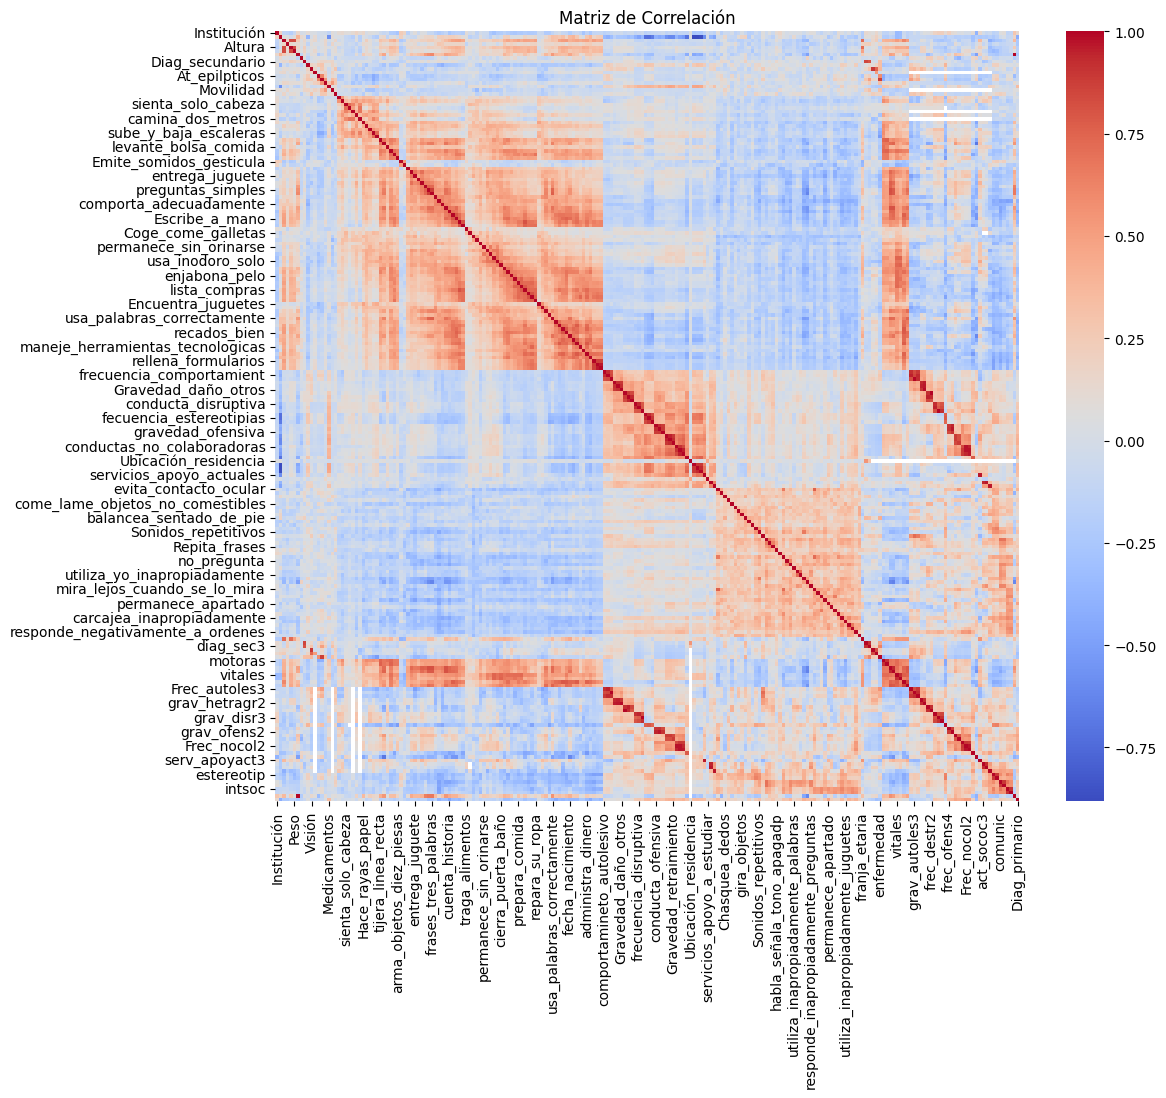

In [16]:
# Hacemos análisis de correlación

# Eliminamos columnas no numéricas para el análisis de correlación
df_numeric = df_sav.select_dtypes(include=['number'])

# Matriz de correlación
corr_matrix = df_numeric.corr()

# Mapa de calor de la matriz de correlación
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de Correlación")
guardar_grafica('03_heatmap_correlacion_general.png')
plt.show()

**NOTA:** Se pueden apreciar distintos cuadrados de un color más intenso, lo que indica que existen grupos de variables con una correlación más alta entre ellas (posiblemente debido a que se corresponden con preguntas de un mismo bloque del cuestionario).
Por ello, y debido a la gran cantidad de variables de este estilo en el dataset, se optará por agruparlas en bloques y calcular una puntuación media para cada bloque.

In [17]:
# 2.3. Feature engineering clínico-psicométrico (ICAP + GARS-2)

# Etiqueta diagnóstica homogénea para todo el notebook
df_sav['Diag_grupo'] = df_sav['Diag_primario'].map({1.0: 'Control', 2.0: 'TEA'})

def columnas_presentes(df, columnas, nombre_bloque):
    presentes = [c for c in columnas if c in df.columns]
    faltantes = [c for c in columnas if c not in df.columns]
    if faltantes:
        print(f"[{nombre_bloque}] Variables no encontradas ({len(faltantes)}): {faltantes}")
    return presentes

# ICAP Parte A (Conducta Adaptativa)

icap_motoras_items = [
    'coger_objetos', 'Pasa_objetos', 'sienta_solo_cabeza', 'mantiene_en_pie',
    'en_pone_en_pie', 'mete_objetos_pequeños', 'camina_dos_metros', 'Hace_rayas_papel',
    'quita_envoltorio', 'gira_manillas', 'sube_y_baja_escaleras', 'sube_escalera_dos_metros',
    'tijera_linea_recta', 'escribe_nombre', 'levante_bolsa_comida', 'sobla_carta_tres',
    'Enhebra_aguja', 'arma_objetos_diez_piesas'
 ]

icap_sociales_items = [
    'Emite_somidos_gesticula', 'tiende_brazos', 'nombre_gira_cabeza', 'imita_acciones',
    'entrega_juguete', 'indica_mueve_cabeza', 'señala_objetos_conocidos', 'dice_10_palabras',
    'preguntas_simples', 'frases_tres_palabras', 'esperar_turno', 'ofrece_ayuda',
    'comporta_adecuadamente', 'reacciona_correctamente_señales', 'cuenta_historia',
    'recuerda_numeros', 'Escribe_a_mano', 'Localiza_informacion', 'Llama_servicio'
 ]

icap_vida_personal_items = [
    'traga_alimentos', 'Coge_come_galletas', 'alarga_vestir', 'mantiene_manos_agua',
    'come_alimentos_solidos', 'permanece_sin_orinarse', 'quita_pantalon', 'Evacua_inodoro',
    'coloca_camisetas', 'usa_inodoro_solo', 'cierra_puerta_baño', 'se_viste_solo',
    'Utiliza_cuchillo', 'enjabona_pelo', 'friega_seca_paltos', 'prepara_comida',
    'arregla_dormitorio', 'lista_compras', 'maneja_lavadora', 'planifica_comida',
    'repara_su_ropa'
 ]

icap_comunidad_items = [
    'Encuentra_juguetes', 'va_solo_cuarto', 'indica_finalizo_tarea', 'espera_sin_alejarse',
    'usa_palabras_correctamente', 'intercambia_objetos', 'compra_objetos', 'barrio_curza_calles',
    'recados_bien', 'fecha_nacimiento', 'Utiliza_reloj', 'cuenta_vuelto_bien',
    'maneje_herramientas_tecnologicas', 'cumple_citas', 'administra_dinero',
    'trabaja_ritmo_regular', 'rellena_formularios', 'recibe_facturas_paga', 'hace_balance_mensual'
 ]

# ICAP Parte B (Conductas Desadaptativas)

icap_conducta_daño_items = [
    'comportamineto_autolesivo', 'frecuencia_comportamient', 'gravedad_comportamiento',
    'heteroagresividad_a_otros', 'frecuencia_daño_otros', 'Gravedad_daño_otros'
 ]

icap_conducta_entorno_items = [
    'destruccion_objetos', 'frecuencia_destruccion', 'gravedad_destruccion',
    'conducta_disruptiva', 'frecuencia_disruptiva', 'gravedad_disruptiva'
 ]

icap_conducta_habitos_items = [
    'habitos_atipicos', 'fecuencia_estereotipias', 'gravedad_estereotipias',
    'Retraimiento_atencion', 'Frecuencia_retraimiento', 'Gravedad_retraimiento'
 ]

# -----------------------------
# GARS-2 (ítems)
# -----------------------------
gars2_estereotipias_items = [
    'evita_contacto_ocular', 'mirar_manos', 'Chasquea_dedos', 'Come_alimentos_especificos',
    'come_lame_objetos_no_comestibles', 'huele_objetos', 'gira_vuelta_circulos', 'gira_objetos',
    'balancea_sentado_de_pie', 'abalanza_moviendose', 'anda_puntillas', 'agita_manos',
    'Sonidos_repetitivos', 'se_golpea'
 ]

gars2_comunicacion_items = [
    'repite_palabras_eco', 'repite_palabras_fuera_contexto', 'Repita_frases', 'habla_señala_tono_apagadp',
    'responde_inapropiadamente', 'evita_mirar_interlocutor', 'no_pregunta', 'no_inicia_conversaciones',
    'utiliza_inapropiadamente_palabras', 'utiliza_inapropiadamente_pronombres', 'utiliza_yo_inapropiadamente',
    'repite_sonidos_ininteligibles', 'utiliza_gesto_no_habla', 'responde_inapropiadamente_preguntas'
 ]

gars2_interaccion_items = [
    'mira_lejos_cuando_se_lo_mira', 'mira_fijamente', 'resiste_contacto_fisico', 'no_imita_otros',
    'permanece_apartado', 'comporta_manera_irrazonable', 'poco_afectuoso', 'no_reconocimiento_persona',
    'carcajea_inapropiadamente', 'utiliza_inapropiadamente_juguetes', 'hacer_cosas_repetidamente',
    'altera_cambio_rutinas', 'responde_negativamente_a_ordenes', 'ordena_objetos_lineas'
 ]

# Bloque Clínico-Funcional

clinico_funcional_items = [
    'Salud', 'At_epilpticos', 'Medicamentos', 'Atencion_enfermero',
    'Apoyos', 'Movilidad', 'Ayudas_movilidad',
    'Visión', 'Audición', 'vis2c', 'Visaud', 'enfermedad'
 ]

# Definición de bloques finales solicitados
nuevos_bloques = {
    'icap_motoras': icap_motoras_items,
    'icap_sociales': icap_sociales_items,
    'icap_vida_personal': icap_vida_personal_items,
    'icap_comunidad': icap_comunidad_items,
    'icap_conducta_daño': icap_conducta_daño_items,
    'icap_conducta_entorno': icap_conducta_entorno_items,
    'icap_conducta_habitos': icap_conducta_habitos_items,
    'gars2_estereotipias': gars2_estereotipias_items,
    'gars2_comunicacion': gars2_comunicacion_items,
    'gars2_interaccion': gars2_interaccion_items,
    'clinico_funcional': clinico_funcional_items
}

# Limpieza de índices previos para evitar mezcla de versiones
for col in list(df_sav.columns):
    if col.startswith('indice_') or col in nuevos_bloques.keys():
        del df_sav[col]

# Construcción de los nuevos índices (media para comparabilidad entre bloques)
for nombre_bloque, lista_items in nuevos_bloques.items():
    cols = columnas_presentes(df_sav, lista_items, nombre_bloque)
    if len(cols) == 0:
        df_sav[nombre_bloque] = np.nan
        print(f"{nombre_bloque}: sin columnas disponibles")
    else:
        df_sav[nombre_bloque] = df_sav[cols].mean(axis=1, skipna=True)
        print(f"{nombre_bloque}: {len(cols)} variables agregadas")

# Alias con prefijo indice_ para compatibilidad con secciones previas del notebook
for nombre_bloque in nuevos_bloques.keys():
    df_sav[f"indice_{nombre_bloque}"] = df_sav[nombre_bloque]

print("\nNuevos bloques creados correctamente.")

icap_motoras: 18 variables agregadas
icap_sociales: 19 variables agregadas
icap_vida_personal: 21 variables agregadas
icap_comunidad: 19 variables agregadas
icap_conducta_daño: 6 variables agregadas
icap_conducta_entorno: 6 variables agregadas
icap_conducta_habitos: 6 variables agregadas
gars2_estereotipias: 14 variables agregadas
gars2_comunicacion: 14 variables agregadas
gars2_interaccion: 14 variables agregadas
clinico_funcional: 12 variables agregadas

Nuevos bloques creados correctamente.


#### 2.3.1. Análisis descriptivo de bloques

A continuación se presenta un análisis descriptivo de los bloques clínicos y funcionales para TEA y Control.

Resumen descriptivo por grupo diagnóstico:


icap_motoras               icap_sociales                \
                   mean median    std          mean median    std   
Diag_grupo                                                          
Control           3.456  3.556  0.543         3.223  3.316  0.689   
TEA               3.333  3.389  0.481         2.672  2.684  0.639   

           icap_vida_personal               icap_comunidad  ...  \
                         mean median    std           mean  ...   
Diag_grupo                                                  ...   
Control                 3.051  3.048  0.681          2.690  ...   
TEA                     2.679  2.667  0.571          2.003  ...   

           clinico_funcional    Edad                 Altura                 \
                         std    mean median    std     mean median     std   
Diag_grupo                                                                   
Control                0.226  11.429   11.0  5.280  139.571  148.0  28.571   
TEA                    0.147   9.108    8.0  4.144  129.315  128.0  30.577   

              Peso                 
              mean median     std  
Diag_grupo                         
Control     43.020   42.5  19.961  
TEA         36.604   32.0  16.827  

[2 rows x 42 columns]

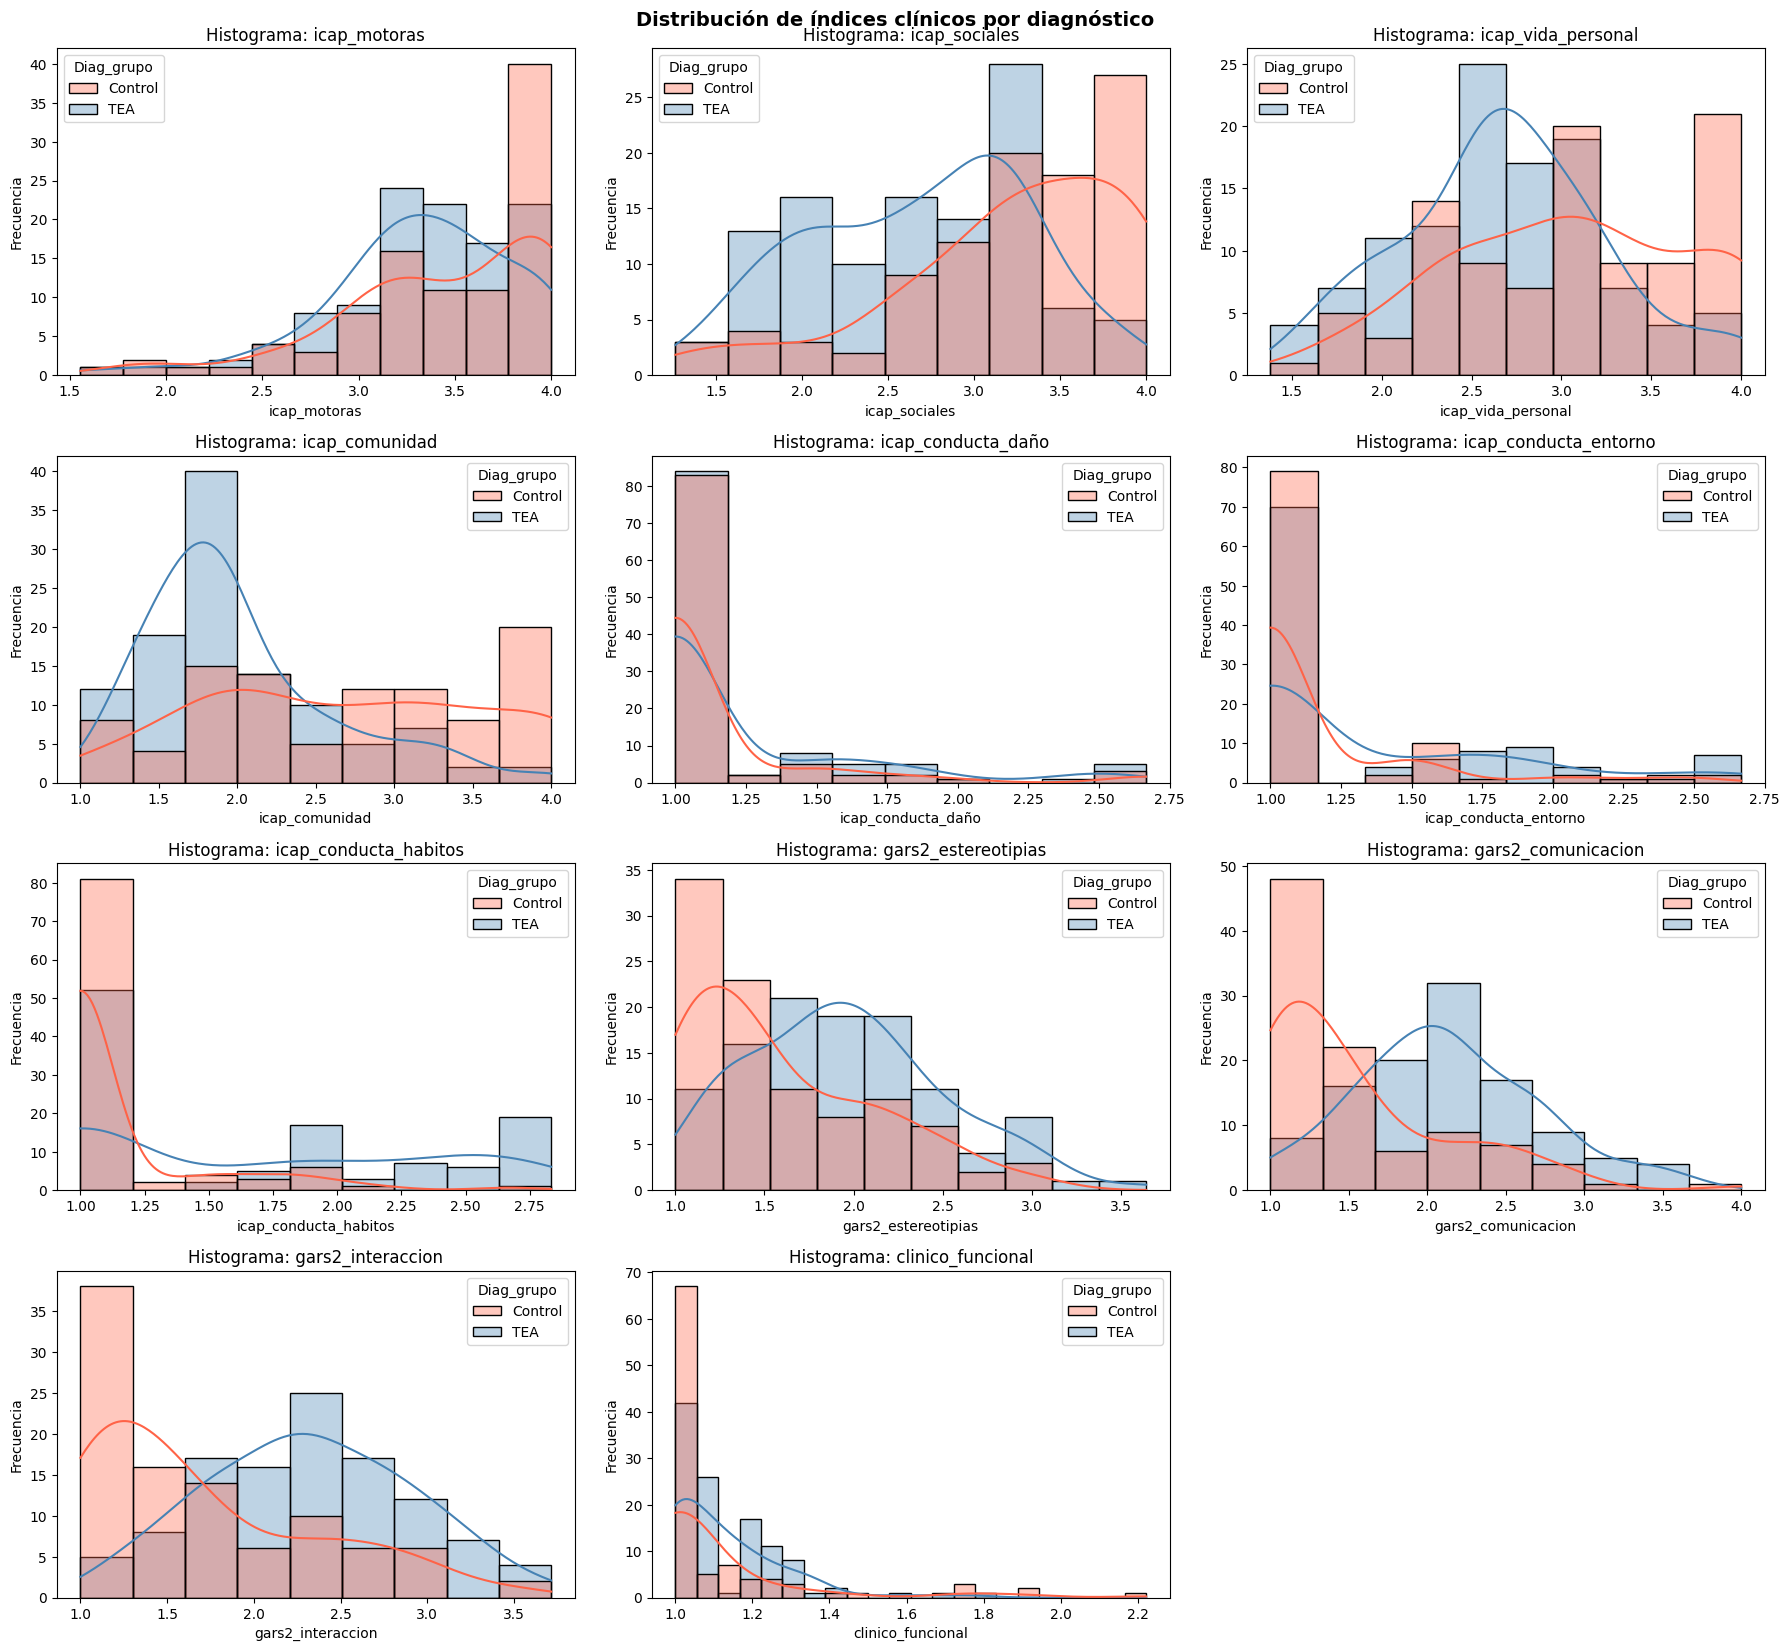

In [18]:
# 2.3.2. Resumen descriptivo y distribuciones (TEA vs Control)

import math

palette_diag = {'TEA': 'steelblue', 'Control': 'tomato'}
orden_diag = ['Control', 'TEA']

df_analisis = df_sav[df_sav['Diag_grupo'].isin(orden_diag)].copy()

bloques_objetivo = [
    'icap_motoras', 'icap_sociales', 'icap_vida_personal', 'icap_comunidad',
    'icap_conducta_daño', 'icap_conducta_entorno', 'icap_conducta_habitos',
    'gars2_estereotipias', 'gars2_comunicacion', 'gars2_interaccion', 'clinico_funcional'
]

variables_resumen = [v for v in bloques_objetivo + ['Edad', 'Altura', 'Peso'] if v in df_analisis.columns]
tabla_resumen = (
    df_analisis
    .groupby('Diag_grupo')[variables_resumen]
    .agg(['mean', 'median', 'std'])
    .round(3)
)

print('Resumen descriptivo por grupo diagnóstico:')
display(tabla_resumen)

# Histogramas para visualizar la forma de distribución por diagnóstico
vars_hist = [v for v in bloques_objetivo if v in df_analisis.columns]
if len(vars_hist) > 0:
    n_cols = 3
    n_rows = math.ceil(len(vars_hist) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.2 * n_rows))
    axes = np.array(axes).reshape(-1)

    for i, var in enumerate(vars_hist):
        sns.histplot(data=df_analisis, x=var, hue='Diag_grupo', kde=True,
                     palette=palette_diag, alpha=0.35, ax=axes[i])
        axes[i].set_title(f'Histograma: {var}')
        axes[i].set_xlabel(var)
        axes[i].set_ylabel('Frecuencia')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle('Distribución de índices clínicos por diagnóstico', fontsize=14, fontweight='bold')
    guardar_grafica('04_histogramas_distribucion_indices.png', fig)
    plt.tight_layout()
    plt.show()
else:
    print('No hay índices agregados disponibles. Ejecuta primero la celda 2.3 de feature engineering.')

#### 2.3.3. Boxplots comparativos de bloques ICAP (TEA vs Control)

Los siguientes gráficos resumen la comparación TEA vs Control para cada bloque ICAP con la misma paleta visual.

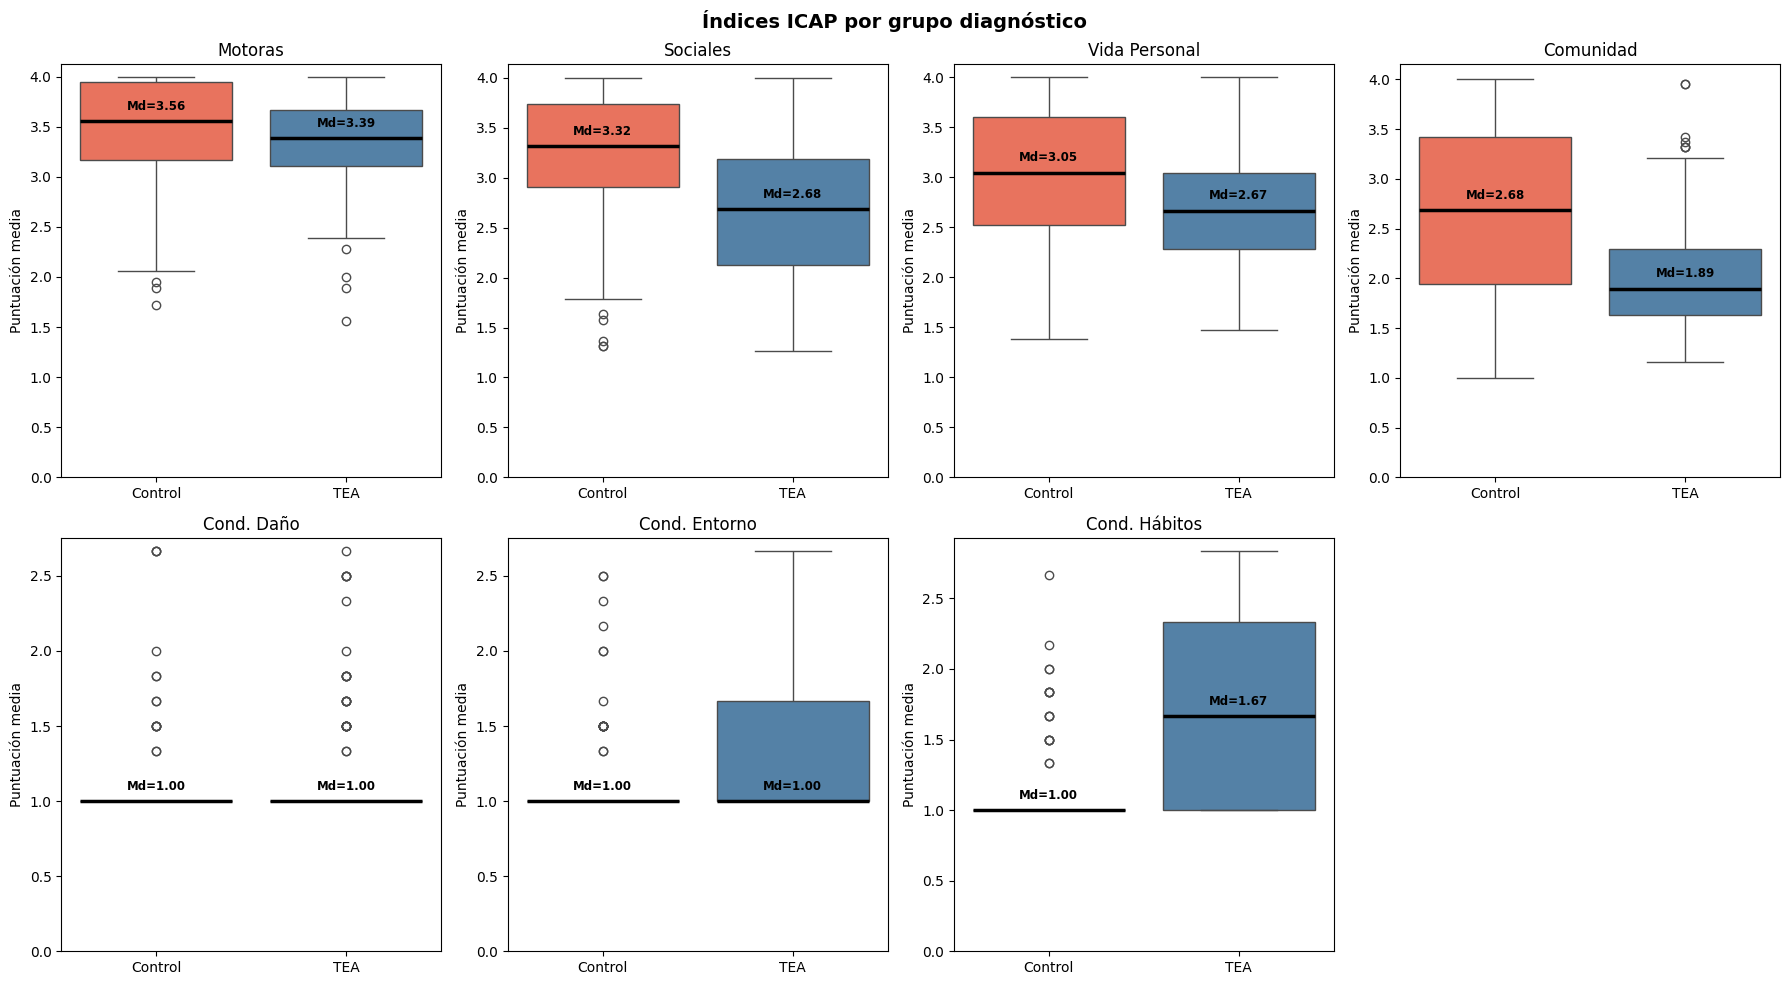

In [19]:
# --- ICAP ---
icap_bloques_plot = [v for v in [
    'icap_motoras', 'icap_sociales', 'icap_vida_personal', 'icap_comunidad',
    'icap_conducta_daño', 'icap_conducta_entorno', 'icap_conducta_habitos'
] if v in df_analisis.columns]

nombres_icap = {
    'icap_motoras':           'Motoras',
    'icap_sociales':          'Sociales',
    'icap_vida_personal':     'Vida Personal',
    'icap_comunidad':         'Comunidad',
    'icap_conducta_daño':     'Cond. Daño',
    'icap_conducta_entorno':  'Cond. Entorno',
    'icap_conducta_habitos':  'Cond. Hábitos',
}

n_cols = 4
n_rows = math.ceil(len(icap_bloques_plot) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = np.array(axes).reshape(-1)

for i, var in enumerate(icap_bloques_plot):
    ax = axes[i]
    sns.boxplot(
        data=df_analisis, x='Diag_grupo', y=var,
        order=orden_diag, hue='Diag_grupo',
        palette=palette_diag, ax=ax,
        dodge=False, legend=False,
        medianprops=dict(color='black', linewidth=2.5)
    )
    ax.set_ylim(bottom=0)
    ax.set_title(nombres_icap.get(var, var), fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('Puntuación media')

    # Anotar mediana encima de cada caja
    for j, grupo in enumerate(orden_diag):
        mediana = df_analisis.loc[df_analisis['Diag_grupo'] == grupo, var].median()
        ax.text(j, mediana + ax.get_ylim()[1] * 0.02,
                f'Md={mediana:.2f}', ha='center', va='bottom',
                fontsize=8.5, fontweight='bold', color='black')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Índices ICAP por grupo diagnóstico', fontsize=14, fontweight='bold')
plt.tight_layout()
guardar_grafica('05_boxplots_icap_tea_vs_control.png', fig)
plt.show()

#### 2.3.4. Violinplots comparativos de bloques ICAP (TEA vs Control)

Estos violinplots complementan los boxplots ICAP mostrando forma de distribución y dispersión dentro de cada grupo diagnóstico.

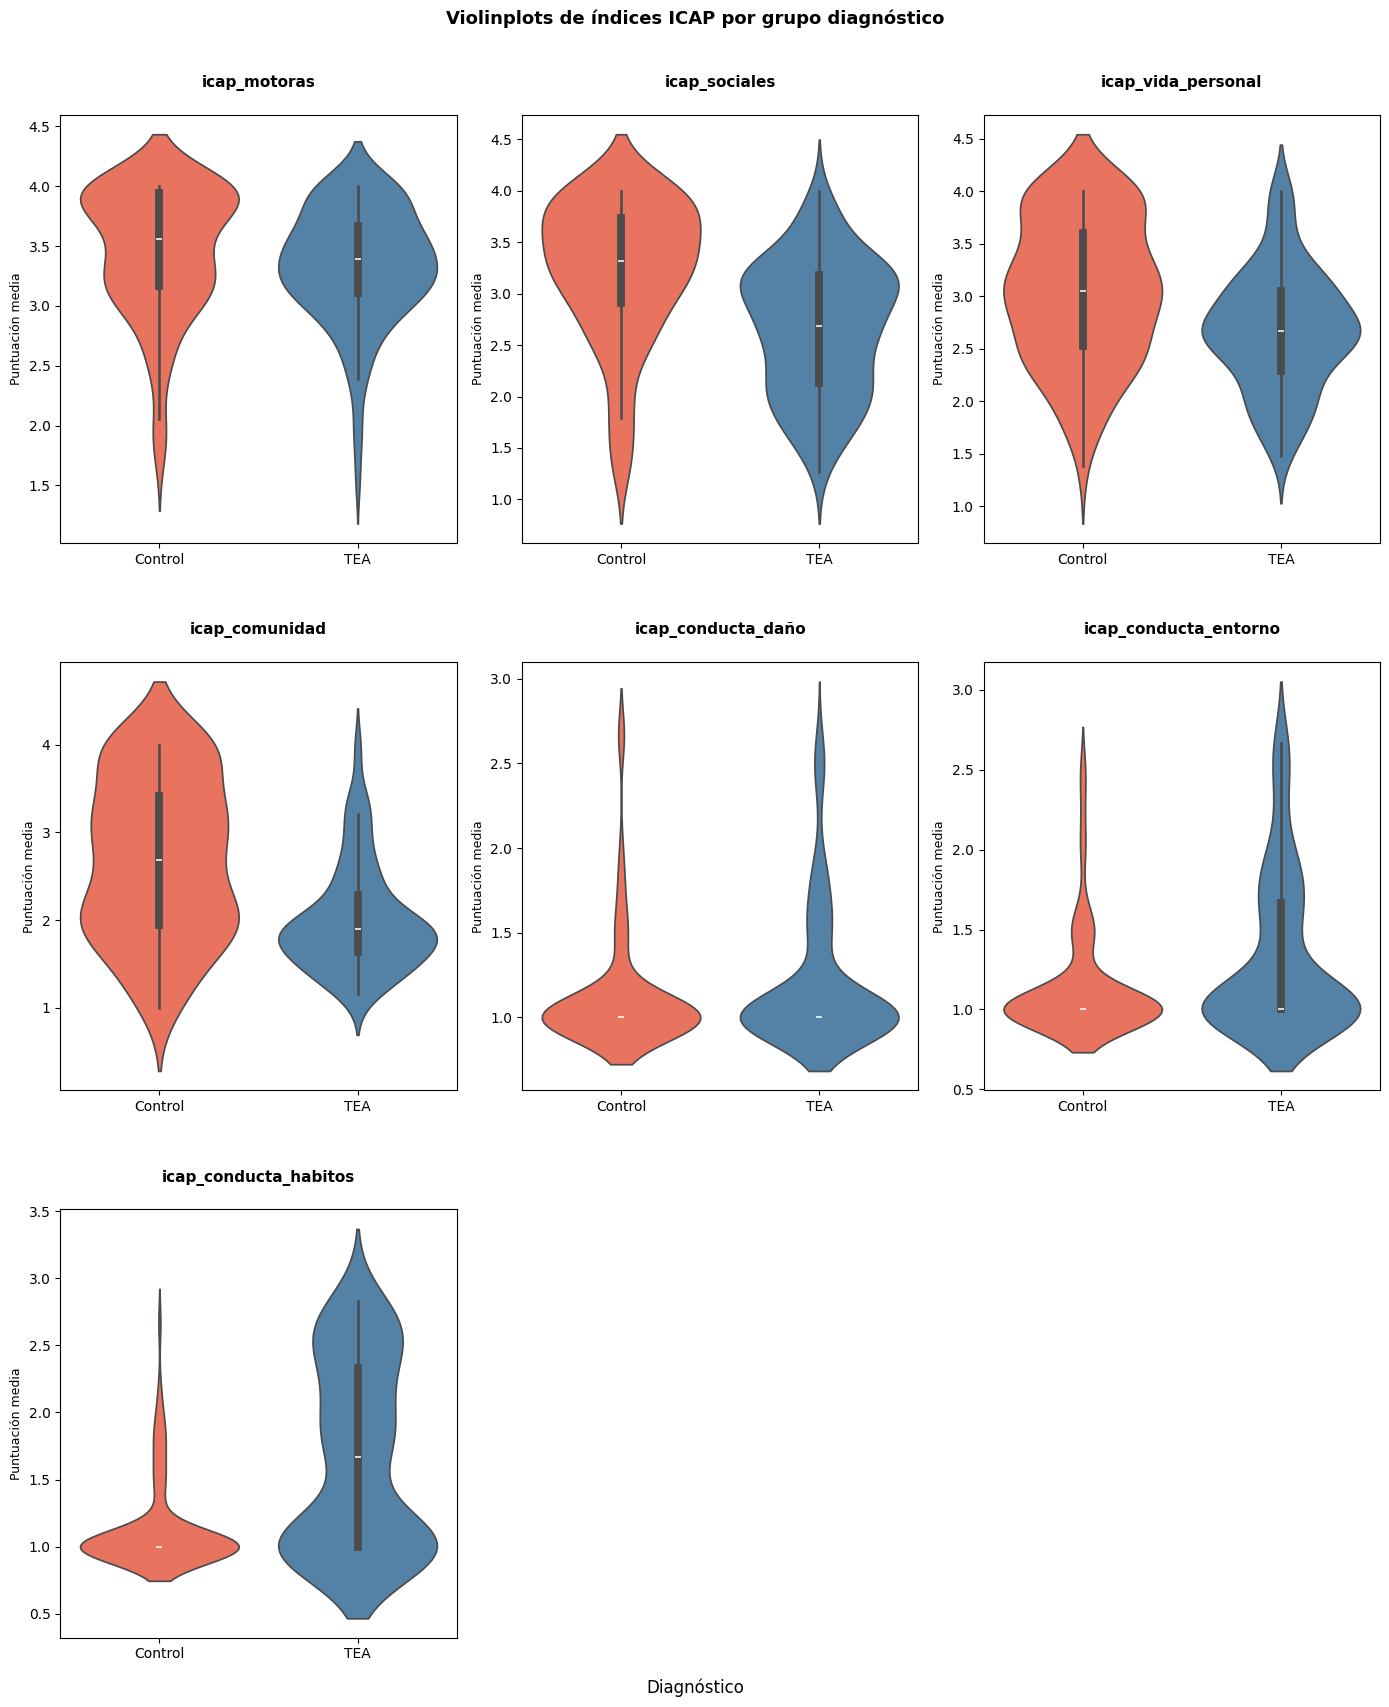

In [20]:
# 2.3.4. Violinplots comparativos ICAP (TEA vs Control)
icap_bloques_plot = [
    c for c in [
        'icap_motoras', 'icap_sociales', 'icap_vida_personal', 'icap_comunidad',
        'icap_conducta_daño', 'icap_conducta_entorno', 'icap_conducta_habitos'
    ] if c in df_sav.columns
]

n_cols = 3
n_rows = math.ceil(len(icap_bloques_plot) / n_cols) if len(icap_bloques_plot) > 0 else 1
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, 5.5 * n_rows))
axes = np.array(axes).reshape(-1)

last_idx = -1
for i, bloque in enumerate(icap_bloques_plot):
    last_idx = i
    ax = axes[i]
    sns.violinplot(
        data=df_sav,
        x='Diag_grupo', y=bloque,
        hue='Diag_grupo',
        order=['Control', 'TEA'],
        palette=PALETA_DIAG,
        ax=ax,
        inner='box',
        legend=False
    )
    # Título encima con espacio generoso; sin xlabel individual
    ax.set_title(bloque, fontsize=11, fontweight='bold', pad=20)
    ax.set_xlabel('')       # sin etiqueta por eje
    ax.set_ylabel('Puntuación media', fontsize=9)
    ax.tick_params(axis='x', labelsize=10)

# Ocultar ejes sobrantes
if last_idx == -1:
    for ax in axes:
        ax.axis('off')
else:
    for j in range(last_idx + 1, len(axes)):
        axes[j].axis('off')

# Etiqueta X compartida para toda la figura
fig.text(0.5, -0.01, 'Diagnóstico', ha='center', fontsize=12)

plt.suptitle('Violinplots de índices ICAP por grupo diagnóstico',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(h_pad=4.0)   # espacio vertical extra entre filas
guardar_grafica('06_violin_icap_por_diagnostico.png', fig)
plt.show()

#### 2.3.5. Boxplots de puntuaciones agregadas GARS-2 por diagnóstico

Se muestran las tres subescalas GARS-2 para comparar visualmente TEA vs Control.

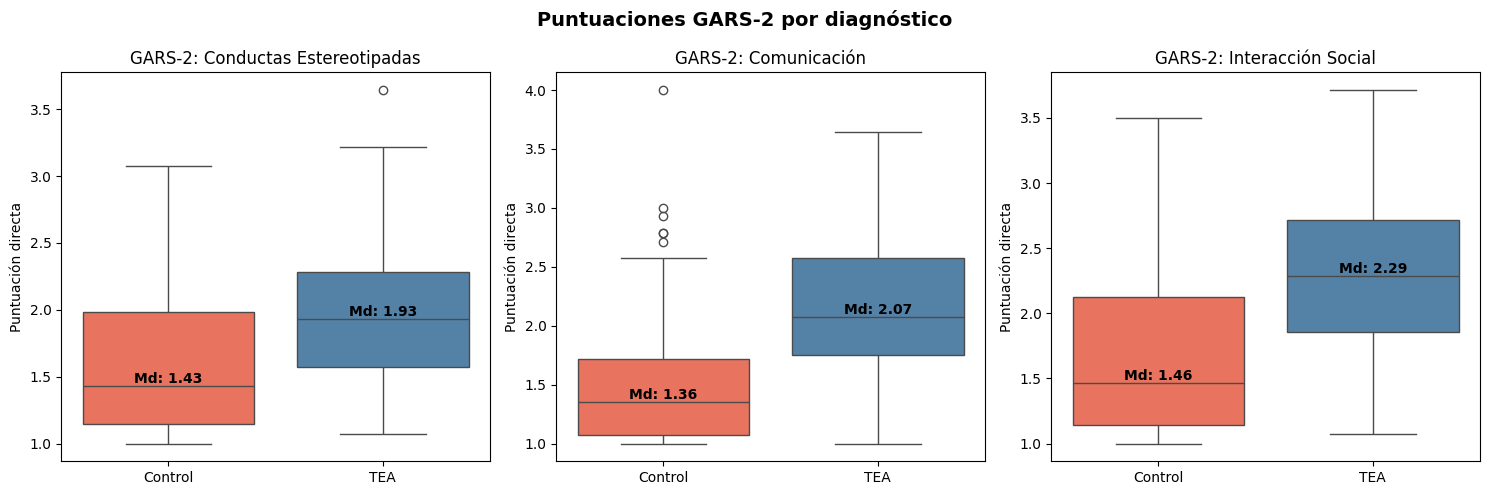

In [24]:
# 2.3.5. Boxplots de puntuaciones agregadas GARS-2 por diagnóstico
gars2_vars = {
    'gars2_estereotipias': 'Conductas Estereotipadas',
    'gars2_comunicacion':  'Comunicación',
    'gars2_interaccion':   'Interacción Social'
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
palette = {'Control': 'tomato', 'TEA': 'steelblue'}

for i, (var, titulo) in enumerate(gars2_vars.items()):
    df_plot = df_sav[['Diag_grupo', var]].dropna()
    sns.boxplot(data=df_plot, x='Diag_grupo', y=var,
                palette=palette, ax=axes[i], order=['Control', 'TEA'])
    axes[i].set_title(f'GARS-2: {titulo}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Puntuación directa')

    for j, grupo in enumerate(['Control', 'TEA']):
        mediana = df_plot[df_plot['Diag_grupo'] == grupo][var].median()
        # Que la mediana esté sobre la línea del medio del boxplot e indicar Mediana: valor
        axes[i].text(j, mediana, f'Md: {mediana:.2f}', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Puntuaciones GARS-2 por diagnóstico', fontsize=14, fontweight='bold')
guardar_grafica('07_boxplots_gars2_por_diagnostico.png', fig)
plt.tight_layout()
plt.show()

#### 2.3.6. Violinplots GARS-2 por diagnóstico

Esta celda complementa los boxplots de GARS-2 mostrando forma de distribución y dispersión individual.

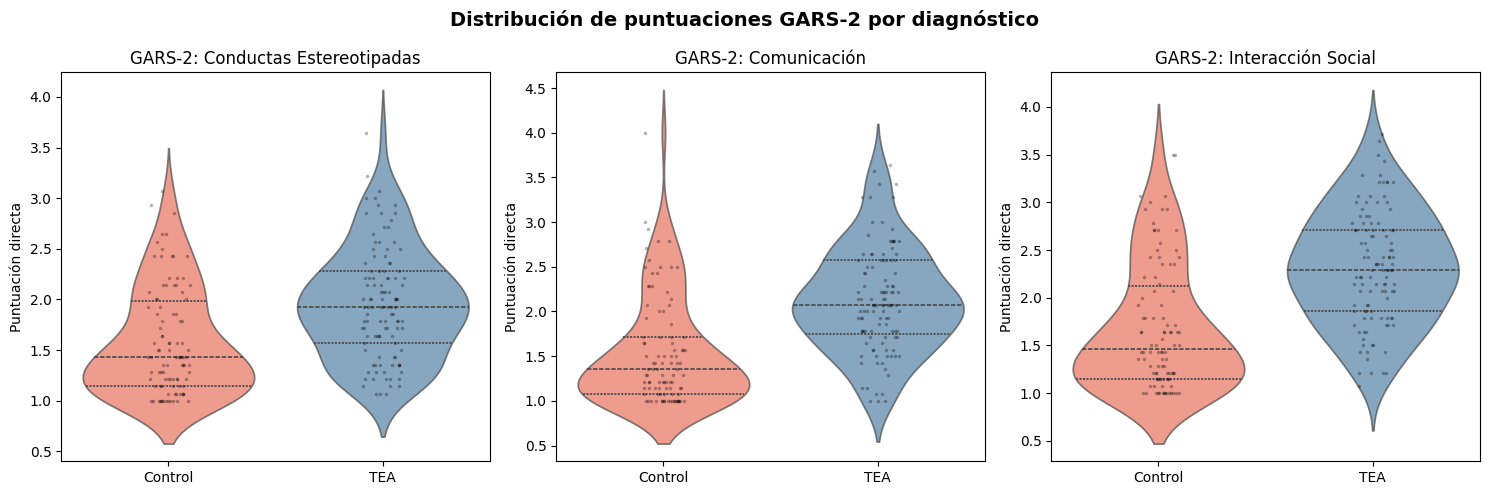

In [50]:
# 2.3.6. Violinplots GARS-2 con puntos individuales superpuestos
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (var, titulo) in enumerate(gars2_vars.items()):
    df_plot = df_sav[['Diag_grupo', var]].dropna()
    sns.violinplot(data=df_plot, x='Diag_grupo', y=var,
                   palette=PALETA_DIAG, ax=axes[i], order=['Control', 'TEA'],
                   inner='quartile', alpha=0.7)
    sns.stripplot(data=df_plot, x='Diag_grupo', y=var,
                  order=['Control', 'TEA'], ax=axes[i],
                  color='black', alpha=0.3, size=2.5, jitter=True)
    axes[i].set_title(f'GARS-2: {titulo}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Puntuación directa')

plt.suptitle('Distribución de puntuaciones GARS-2 por diagnóstico', fontsize=14, fontweight='bold')
guardar_grafica('08_violin_gars2_por_diagnostico.png', fig)
plt.tight_layout()
plt.show()

#### 2.3.7. Correlaciones entre bloques

Se usa Spearman para estimar relaciones entre índices clínico-funcionales respetando su naturaleza ordinal/no normal.

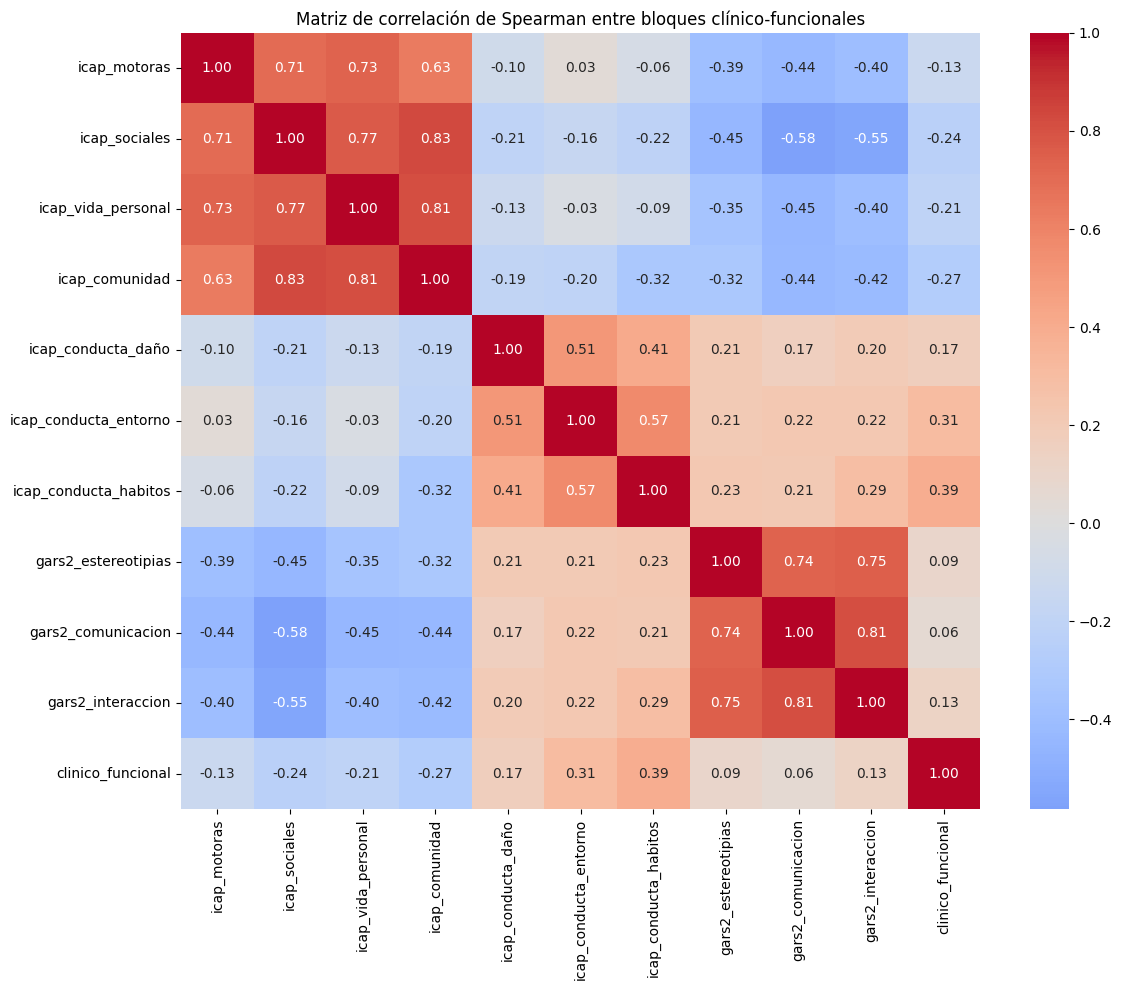

In [51]:
# 2.3.7. Correlaciones entre bloques (Spearman)

vars_spearman = [v for v in nuevos_bloques if v in df_analisis.columns]

corr_spearman = df_analisis[vars_spearman].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(corr_spearman, cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Matriz de correlación de Spearman entre bloques clínico-funcionales')
guardar_grafica('09_heatmap_spearman_bloques.png')
plt.tight_layout()
plt.show()

**NOTA:** Se observa en el mapa de calor que existen correlaciones positivas moderadas y altas entre las puntuaciones medias de varios bloques de preguntas, lo que indica que los participantes que obtienen puntuaciones altas en ciertos bloques tienden a obtener puntuaciones altas en otros bloques también. En el gráfico, se diferencian claramente dos grandes grupos de bloques con alta correlación entre ellos.

#### 2.4. Distribución conjunta de edad y franja etaria con diagnóstico

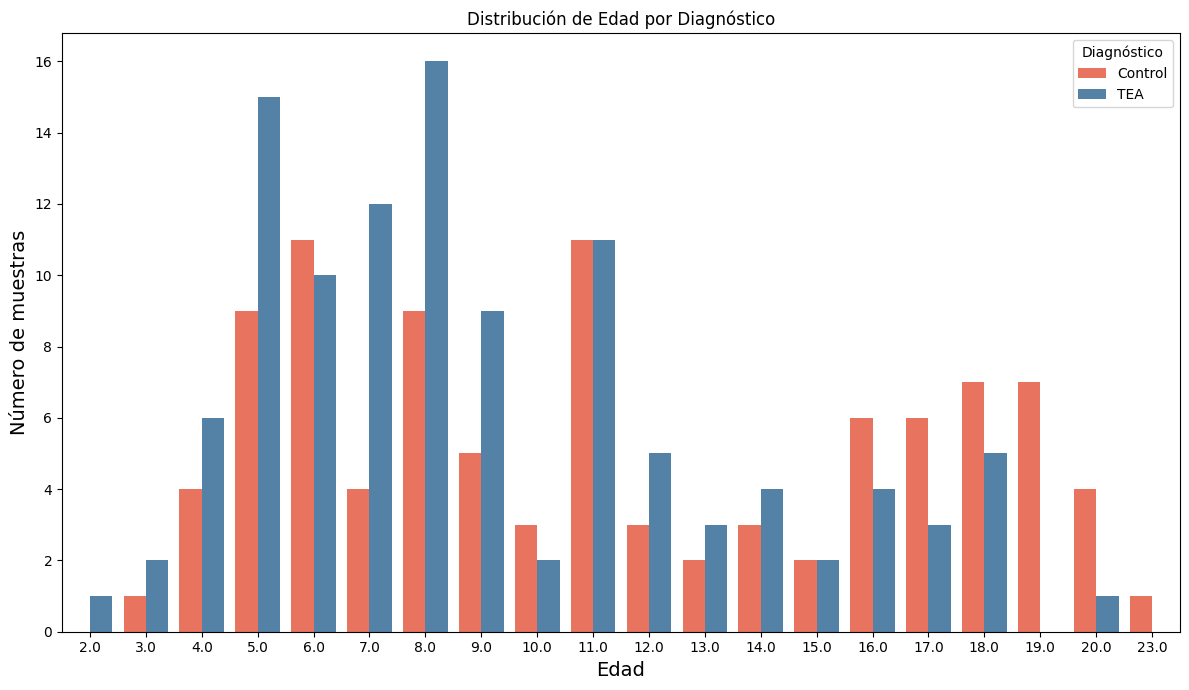

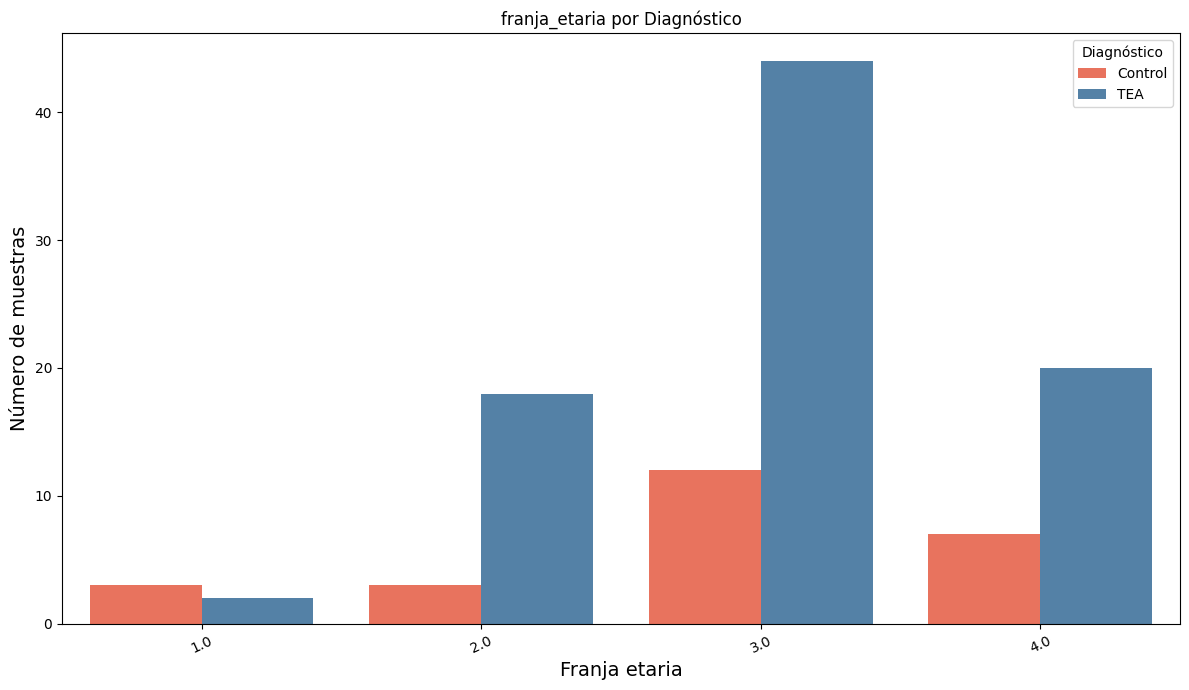

In [52]:
# Distribución de Edad continua y franja_etaria con diagnóstico

# A) Edad continua
fig_edad, ax_edad = plt.subplots(1, 1, figsize=(12, 7))
sns.countplot(
    data=df_sav,
    x='Edad',
    hue='Diag_grupo',
    palette=PALETA_DIAG,
    hue_order=['Control', 'TEA'],
    ax=ax_edad
)
ax_edad.set_title('Distribución de Edad por Diagnóstico')
ax_edad.set_xlabel('Edad', size=14)
ax_edad.set_ylabel('Número de muestras', size=14)
ax_edad.legend(title='Diagnóstico')
guardar_grafica('10_edad_por_diagnostico.png', fig_edad)
plt.tight_layout()
plt.show()

# B) franja_etaria (ordinal)
if 'franja_etaria' in df_sav.columns:
    franja_map = meta.variable_value_labels.get('franja_etaria', {})

    if len(franja_map) > 0:
        df_sav['franja_etaria_label'] = df_sav['franja_etaria'].map(franja_map)
        orden_franjas = [franja_map[k] for k in sorted(franja_map.keys())]
        x_col = 'franja_etaria_label'
    else:
        x_col = 'franja_etaria'
        orden_franjas = sorted(df_sav['franja_etaria'].dropna().unique())

    fig_franja, ax_franja = plt.subplots(1, 1, figsize=(12, 7))
    sns.countplot(
        data=df_sav,
        x=x_col,
        hue='Diag_grupo',
        order=orden_franjas,
        palette=PALETA_DIAG,
        hue_order=['Control', 'TEA'],
        ax=ax_franja
    )

    ax_franja.set_title('franja_etaria por Diagnóstico')
    ax_franja.set_xlabel('Franja etaria', size=14)
    ax_franja.set_ylabel('Número de muestras', size=14)
    ax_franja.tick_params(axis='x', rotation=25)
    ax_franja.legend(title='Diagnóstico')

    guardar_grafica('11_franja_etaria_por_diagnostico.png', fig_franja)
    plt.tight_layout()
    plt.show()
else:
    print("La variable 'franja_etaria' no está disponible en el dataframe.")

**NOTA:** Se observa que la mayoría de los participantes tienen entre 5 y 11 años. Además, se aprecia que el diagnóstico de TEA es más frecuente en edades tempranas, lo cual es consistente con la literatura existente sobre el trastorno.

#### 2.5. Distribución conjunta de altura y peso con diagnóstico

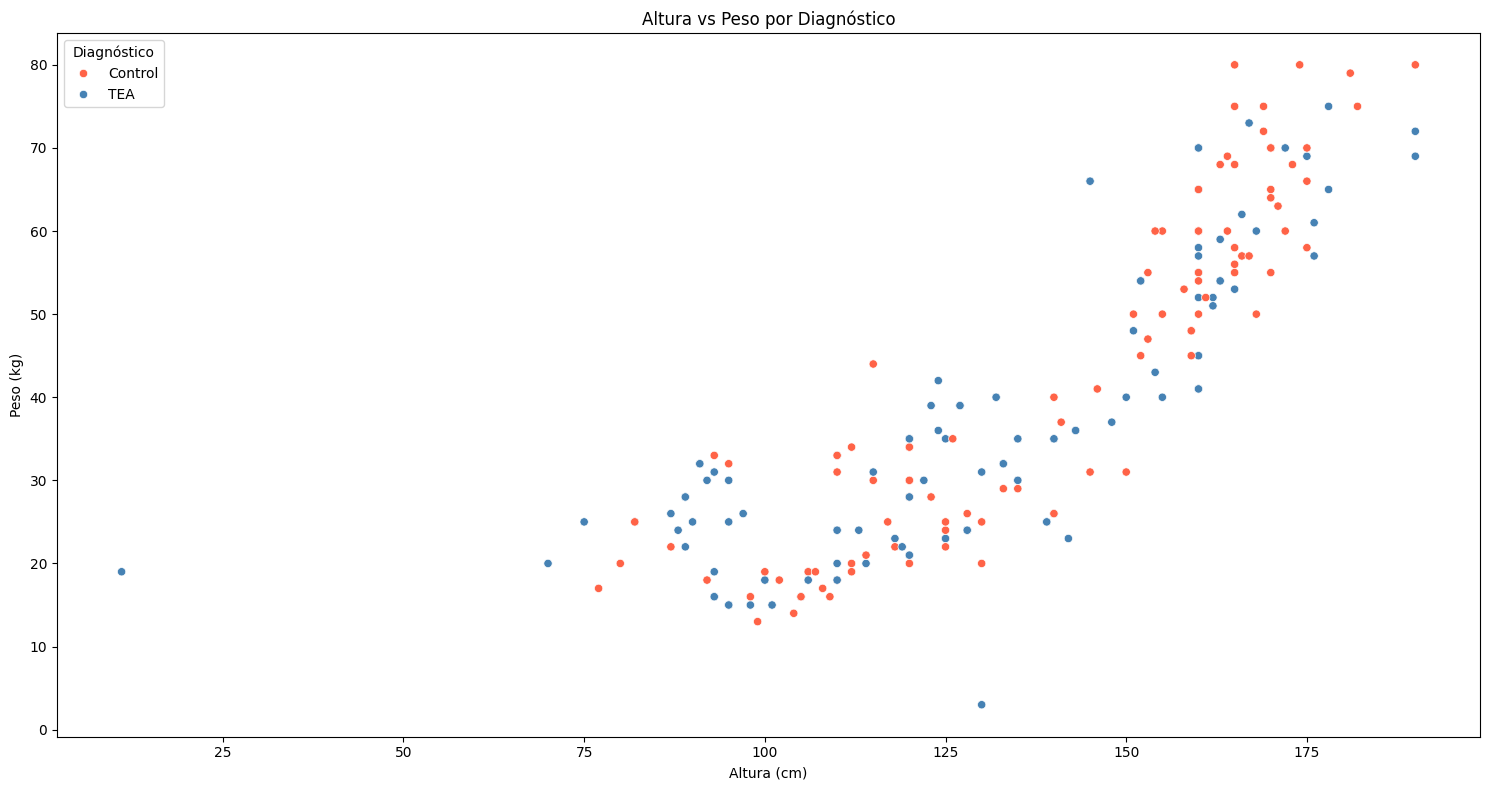

In [53]:
# Scatter plot con altura y peso, coloreado por diagnóstico

plt.figure(figsize=(15, 8))
sns.scatterplot(
    data=df_sav,
    x='Altura', y='Peso',
    hue='Diag_grupo',
    palette=PALETA_DIAG,
    hue_order=['Control', 'TEA']
 )

plt.title("Altura vs Peso por Diagnóstico")
plt.xlabel("Altura (cm)")
plt.ylabel("Peso (kg)")
plt.legend(title='Diagnóstico', loc='upper left')
guardar_grafica('12_altura_peso_por_diagnostico.png')
plt.tight_layout()
plt.show()

**NOTA:** A partir del gráfico de puntos no se puede concluir que exista una relación clara entre el peso y la altura de los participantes y el diagnóstico de TEA.

#### 2.6. Distribución conjunta de modo de expresión y nivel de apoyos con diagnóstico

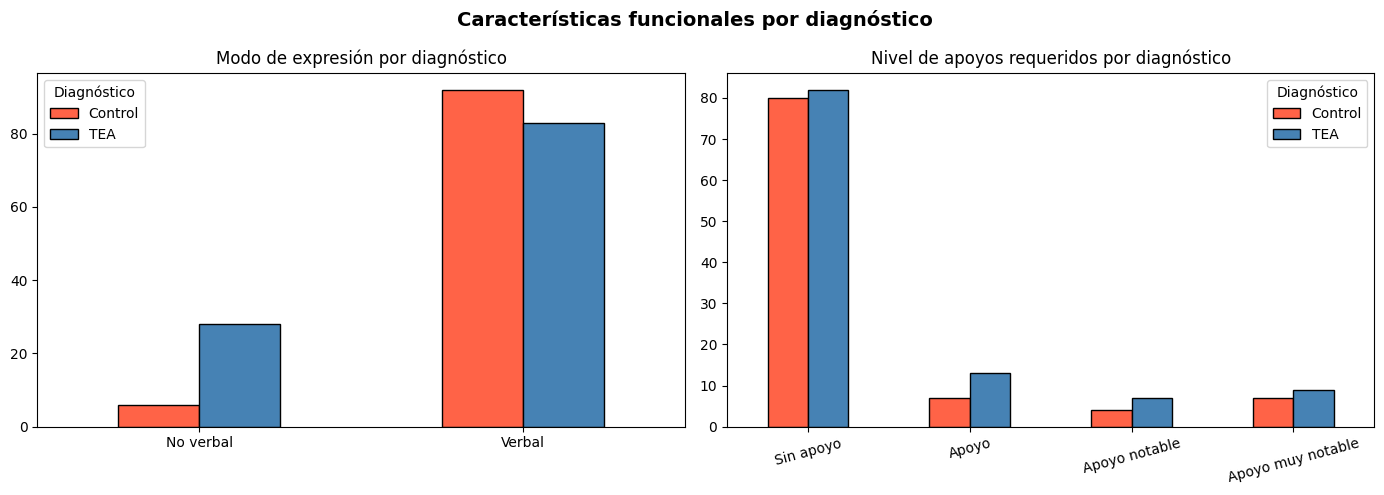

In [54]:
# Modo de expresión y nivel de apoyos por diagnóstico
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

expresion_labels = {1.0: 'No verbal', 2.0: 'Verbal'}
apoyos_labels    = {1.0: 'Sin apoyo', 2.0: 'Apoyo', 3.0: 'Apoyo notable', 4.0: 'Apoyo muy notable'}

df_sav['Expresion_label'] = df_sav['M_expresion'].map(expresion_labels)
df_sav['Apoyos_label']    = df_sav['Apoyos'].map(apoyos_labels)

# Modo de expresión
conteo_exp = df_sav.groupby(['Expresion_label', 'Diag_grupo']).size().unstack(fill_value=0)
conteo_exp = conteo_exp.reindex(columns=['Control', 'TEA'])
conteo_exp.plot(kind='bar', ax=axes[0], color=[PALETA_DIAG['Control'], PALETA_DIAG['TEA']],
                edgecolor='black', rot=0)
axes[0].set_title('Modo de expresión por diagnóstico')
axes[0].set_xlabel('')
axes[0].legend(title='Diagnóstico')

# Nivel de apoyos
orden_apoyos = ['Sin apoyo', 'Apoyo', 'Apoyo notable', 'Apoyo muy notable']
conteo_apoyos = df_sav.groupby(['Apoyos_label', 'Diag_grupo']).size().unstack(fill_value=0)
conteo_apoyos = conteo_apoyos.reindex([a for a in orden_apoyos if a in conteo_apoyos.index])
conteo_apoyos = conteo_apoyos.reindex(columns=['Control', 'TEA'])
conteo_apoyos.plot(kind='bar', ax=axes[1], color=[PALETA_DIAG['Control'], PALETA_DIAG['TEA']],
                   edgecolor='black', rot=15)
axes[1].set_title('Nivel de apoyos requeridos por diagnóstico')
axes[1].set_xlabel('')
axes[1].legend(title='Diagnóstico')

plt.suptitle('Características funcionales por diagnóstico', fontsize=14, fontweight='bold')
guardar_grafica('13_expresion_apoyos_por_diagnostico.png', fig)
plt.tight_layout()
plt.show()

#### 2.7. Reducción de dimensionalidad mediante PCA, t-SNE y UMAP

##### 2.7.1. Con todas las características

Eliminadas 22 variables agregadas.
Variables restantes (originales): 216
OK: análisis con 216 variables (objetivo excluida).


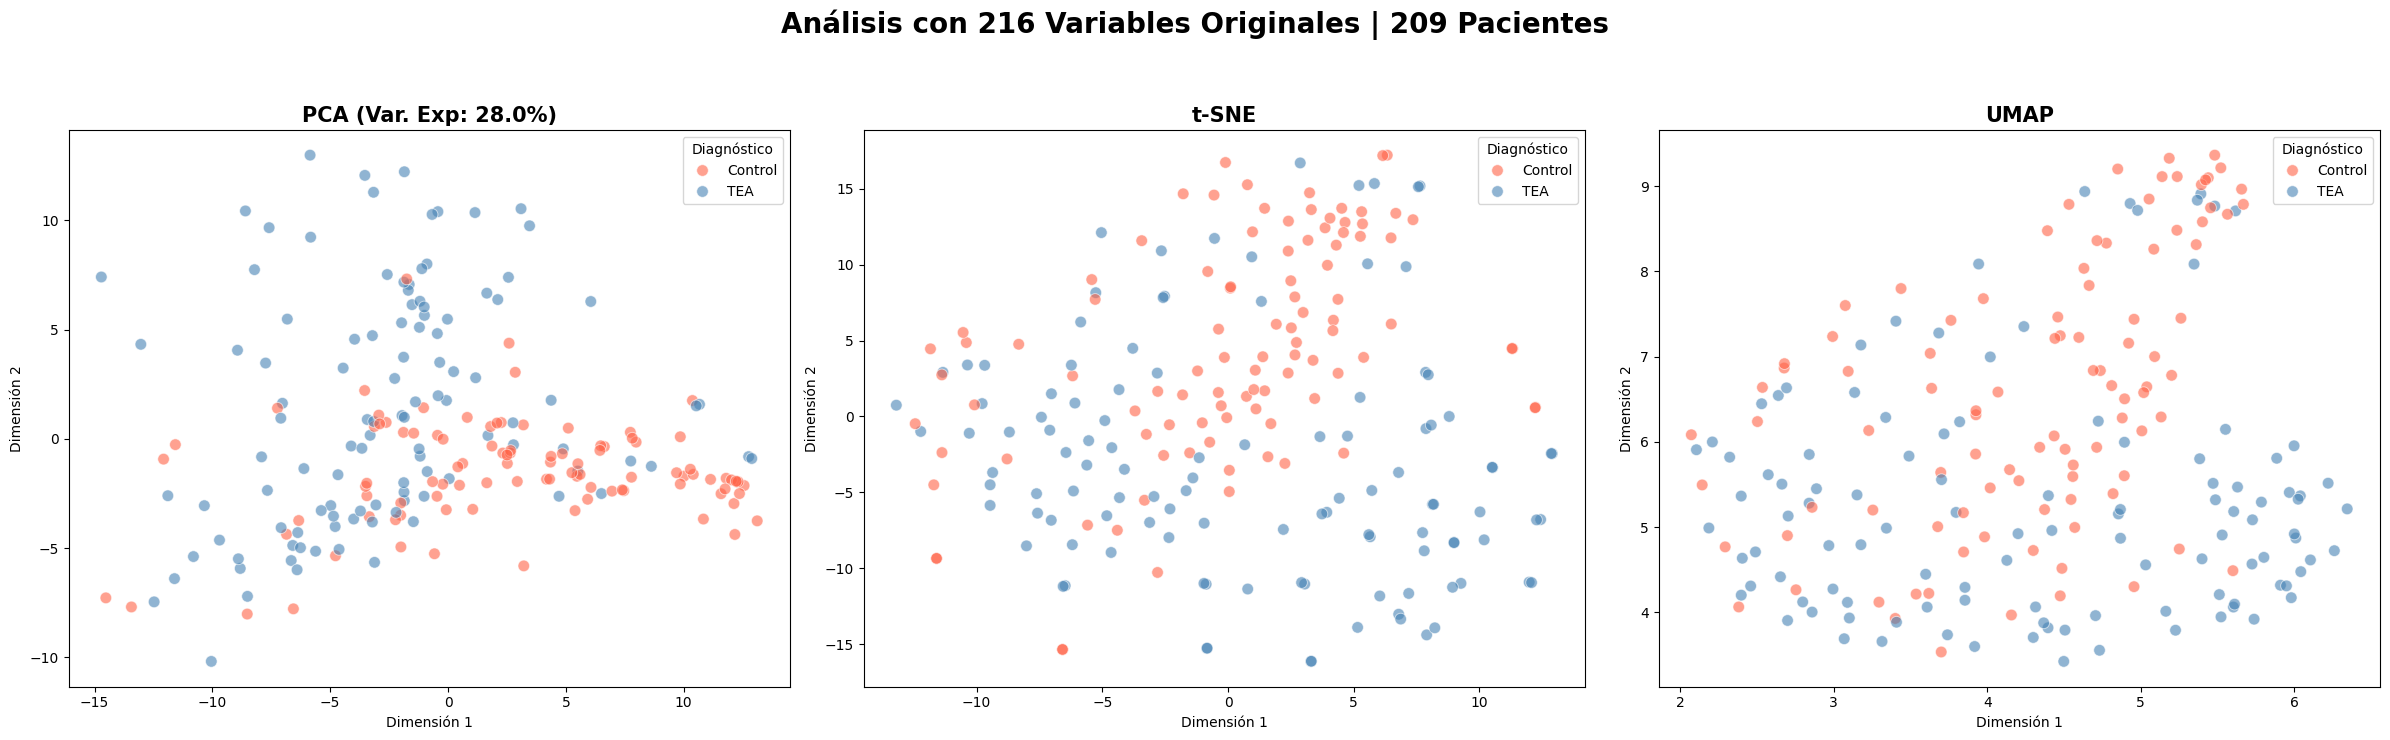

In [55]:
# ANÁLISIS DE SEPARABILIDAD: VARIABLES ORIGINALES (SIN AGRUPAMIENTOS)

# 1. PREPARACIÓN DE VARIABLES
# Objetivo + columnas auxiliares creadas en el notebook (no deben entrar como predictores)
cols_auxiliares = ['Diag_grupo', 'Pais_label', 'Sexo_label', 'Expresion_label', 'Apoyos_label', 'franja_etaria_label']
X_raw = df_sav.drop(columns=['Diag_primario', *cols_auxiliares], errors='ignore')

# Eliminamos índices agregados para trabajar solo con variables originales
cols_indices = [c for c in X_raw.columns if c.startswith('indice_') or c in nuevos_bloques]
X_raw = X_raw.drop(columns=cols_indices, errors='ignore')

print(f"Eliminadas {len(cols_indices)} variables agregadas.")
print(f"Variables restantes (originales): {X_raw.shape[1]}")

n_esperado = 216
if X_raw.shape[1] == n_esperado:
    print(f"OK: análisis con {n_esperado} variables (objetivo excluida).")
else:
    print(f"ADVERTENCIA: se esperaban {n_esperado} variables y se han obtenido {X_raw.shape[1]}.")

# 2. CODIFICACIÓN DE CATEGÓRICAS
for col in X_raw.select_dtypes(include=['category', 'object']).columns:
    X_raw[col] = X_raw[col].astype('category').cat.codes

# 3. IMPUTACIÓN Y ESCALADO
imputador = KNNImputer(n_neighbors=5)
X_imputed = imputador.fit_transform(X_raw)
X_scaled = StandardScaler().fit_transform(X_imputed)

# Etiquetas de diagnóstico homogéneas
y_labels = df_sav['Diag_grupo'].fillna('Control')
palette = {'Control': 'tomato', 'TEA': 'steelblue'}

# 4. REDUCCIÓN DE DIMENSIONALIDAD
reducers = {
    'PCA': PCA(n_components=2, random_state=42),
    't-SNE': TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto', perplexity=30),
    'UMAP': umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
}

# 5. PANEL VISUAL
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for i, (name, model) in enumerate(reducers.items()):
    emb = model.fit_transform(X_scaled)
    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1],
        hue=y_labels,
        hue_order=['Control', 'TEA'],
        palette=palette,
        alpha=0.6,
        s=70,
        ax=axes[i],
        edgecolor='w'
    )

    titulo = f"{name}"
    if name == 'PCA':
        titulo += f" (Var. Exp: {model.explained_variance_ratio_.sum()*100:.1f}%)"

    axes[i].set_title(titulo, fontsize=15, fontweight='bold')
    axes[i].set_xlabel('Dimensión 1')
    axes[i].set_ylabel('Dimensión 2')
    axes[i].legend(title='Diagnóstico')

plt.suptitle(f"Análisis con {X_raw.shape[1]} Variables Originales | {X_raw.shape[0]} Pacientes",
             fontsize=20, fontweight='bold', y=1.05)
guardar_grafica('14_reduccion_dimensionalidad_variables_originales.png', fig)
plt.tight_layout()
plt.show()

##### 2.7.2. Con puntuaciones medias de bloques de preguntas

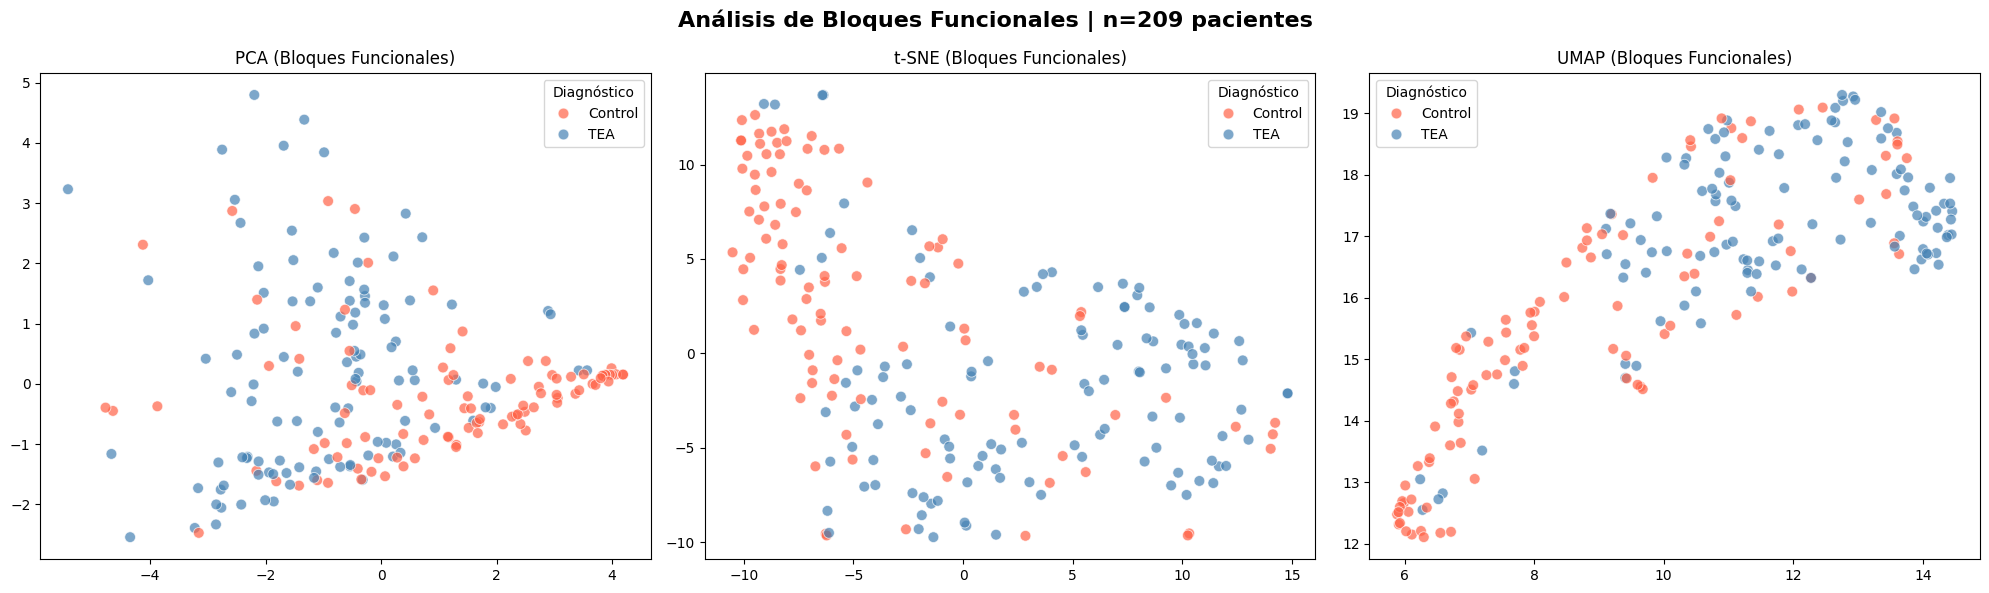

In [56]:
# Reducción de dimensionalidad con los bloques funcionales (TODOS LOS PACIENTES)

# 1. Filtramos los bloques funcionales
df_bloques_raw = df_sav[[c for c in nuevos_bloques if c in df_sav.columns]]

# 2. Imputamos y Escalamos
imputer = KNNImputer(n_neighbors=5)
scaler = StandardScaler()

X_bloques = scaler.fit_transform(imputer.fit_transform(df_bloques_raw))
labels_nombres = df_sav['Diag_grupo'].fillna('Control')

# 3. Diccionario de métodos
reducers = {
    "PCA": PCA(n_components=2, random_state=42),
    "t-SNE": TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto'),
    "UMAP": umap.UMAP(n_components=2, random_state=42)
}

# 4. Gráficas
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
palette = {'Control': 'tomato', 'TEA': 'steelblue'}

for i, (name, model) in enumerate(reducers.items()):
    emb = model.fit_transform(X_bloques)
    sns.scatterplot(
        x=emb[:,0], y=emb[:,1],
        hue=labels_nombres,
        hue_order=['Control', 'TEA'],
        palette=palette,
        alpha=0.7, s=60, ax=axes[i]
    )
    axes[i].set_title(f"{name} (Bloques Funcionales)")
    axes[i].legend(title="Diagnóstico")

plt.suptitle(f"Análisis de Bloques Funcionales | n={len(X_bloques)} pacientes", fontsize=16, fontweight='bold')
guardar_grafica('15_reduccion_dimensionalidad_bloques_funcionales.png', fig)
plt.tight_layout()
plt.show()

**NOTA:** En ambas reducciones de dimensionalidad no se observa una separación clara entre los participantes con diagnóstico de TEA y los que no lo tienen, lo que indica que las características actuales no permiten distinguir fácilmente entre ambos grupos.